# Three-Perspective Thematic Comparison of ML-OPF Research

## 1. Setup and Paths

This notebook integrates the final topic-modeling outputs from the academic
Scopus corpus, the patent-cited corpus, and the policy-cited corpus.

No LDA models are estimated in this notebook. Instead, previously estimated
topic models are loaded, harmonized into a common macro-theme taxonomy, and
compared across the three research perspectives.

The three perspectives are:

- **Academic research:** full Scopus ML--OPF corpus.
- **Patent-cited research:** Scopus publications identified as cited by patents through Lens.
- **Policy-cited research:** Scopus publications identified as cited by policy documents through Overton.

The final objective is to construct a common thematic comparison of academic,
patent, and policy perspectives using probability-weighted topic prevalence.

In [2]:
# ---------------------------------------------------------
# Imports
# ---------------------------------------------------------

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

In [3]:
# ---------------------------------------------------------
# Project directories
# ---------------------------------------------------------

PROJECT_DIR = Path(
    r"M:\projects_latex\review_paper_2"
)


DATA_DIR = (
    PROJECT_DIR
    / "data"
)


OUTPUT_DIR = (
    PROJECT_DIR
    / "output"
)


FIGURE_DIR = (
    PROJECT_DIR
    / "figs"
)


# ---------------------------------------------------------
# Existing topic-modeling output directories
# ---------------------------------------------------------

PATENT_POLICY_TOPIC_DIR = (
    OUTPUT_DIR
    / "patent_policy_topic_modeling"
)


PATENT_POLICY_LDA_DIR = (
    PATENT_POLICY_TOPIC_DIR
    / "lda"
)
# ---------------------------------------------------------
# Inspect existing output directories
# ---------------------------------------------------------

print(
    "Project directory:",
    PROJECT_DIR
)


print(
    "Output directory:",
    OUTPUT_DIR
)


print()
print(
    "Output subdirectories:"
)


for path in sorted(
    OUTPUT_DIR.iterdir()
):

    if path.is_dir():

        print(
            " -",
            path.name
        )

Project directory: M:\projects_latex\review_paper_2
Output directory: M:\projects_latex\review_paper_2\output

Output subdirectories:
 - academic_patent_policy_comparison
 - domain_filtered_metadata
 - figures
 - lda
 - meta_theme_analysis
 - patent_policy_citation_landscape
 - patent_policy_topic_modeling
 - r_preprocessing
 - scopus_research_landscape
 - temporal_analysis
 - topic_interpretation
 - topic_prevalence


In [4]:
# ---------------------------------------------------------
# Three-perspective comparison output
# ---------------------------------------------------------

THREE_PERSPECTIVE_DIR = (
    OUTPUT_DIR
    / "academic_patent_policy_comparison"
)


TABLE_DIR = (
    THREE_PERSPECTIVE_DIR
    / "tables"
)


COMPARISON_FIGURE_DIR = (
    THREE_PERSPECTIVE_DIR
    / "figures"
)


THREE_PERSPECTIVE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


COMPARISON_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


print(
    "Comparison output:",
    THREE_PERSPECTIVE_DIR
)


print(
    "Tables:",
    TABLE_DIR
)


print(
    "Figures:",
    COMPARISON_FIGURE_DIR
)

Comparison output: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison
Tables: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\tables
Figures: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\figures


In [5]:
# ---------------------------------------------------------
# Patent/policy final topic files
# ---------------------------------------------------------

PATENT_TOPIC_FILE = (
    PATENT_POLICY_LDA_DIR
    / "patent_cited_final_topic_interpretation.csv"
)


POLICY_TOPIC_FILE = (
    PATENT_POLICY_LDA_DIR
    / "policy_cited_final_topic_interpretation.csv"
)

PATENT_POLICY_MACRO_FILE = (
    PATENT_POLICY_LDA_DIR
    / "patent_policy_macro_theme_table.csv"
)

In [6]:
# ---------------------------------------------------------
# Validate known input files
# ---------------------------------------------------------

known_input_files = {

    "Patent topic interpretation":
        PATENT_TOPIC_FILE,

    "Policy topic interpretation":
        POLICY_TOPIC_FILE,

    "Patent-policy macro-theme table":
        PATENT_POLICY_MACRO_FILE,
}


for name, path in known_input_files.items():

    print(
        f"{name:<38}",
        "FOUND"
        if path.exists()
        else "MISSING",
    )

    print(
        "   ",
        path
    )

Patent topic interpretation            FOUND
    M:\projects_latex\review_paper_2\output\patent_policy_topic_modeling\lda\patent_cited_final_topic_interpretation.csv
Policy topic interpretation            FOUND
    M:\projects_latex\review_paper_2\output\patent_policy_topic_modeling\lda\policy_cited_final_topic_interpretation.csv
Patent-policy macro-theme table        FOUND
    M:\projects_latex\review_paper_2\output\patent_policy_topic_modeling\lda\patent_policy_macro_theme_table.csv


In [7]:
# ---------------------------------------------------------
# Display settings
# ---------------------------------------------------------

pd.set_option(
    "display.max_columns",
    None,
)


pd.set_option(
    "display.max_colwidth",
    120,
)


pd.set_option(
    "display.width",
    200,
)

## 2. Load Final Academic Topic Results

The academic perspective is represented by the final \(K=50\) LDA model
estimated on the full Scopus ML--OPF corpus.

For the three-perspective comparison, the analysis returns to the 50
fine-grained academic topics rather than using the previously aggregated
academic macro-themes. Each academic topic will subsequently be mapped to
the same common macro-theme taxonomy used for the patent- and policy-cited
corpora.

The required information for each topic is:

- topic identifier;
- probability-weighted prevalence;
- manually assigned topic label;
- highest-probability terms; and
- representative publication titles.

In [8]:
# ---------------------------------------------------------
# Locate existing academic topic-modeling outputs
# ---------------------------------------------------------

print(
    "Searching for academic topic outputs..."
)

print()


candidate_files = []


for path in OUTPUT_DIR.rglob(
    "*.csv"
):

    name_lower = (
        path.name
        .lower()
    )

    if any(
        keyword in name_lower
        for keyword in [
            "topic",
            "prevalence",
            "interpret",
            "scopus",
            "academic",
        ]
    ):

        candidate_files.append(
            path
        )


for path in sorted(
    candidate_files
):

    print(
        path.relative_to(
            PROJECT_DIR
        )
    )

Searching for academic topic outputs...

output\academic_patent_policy_comparison\tables\academic_common_macro_theme_summary.csv
output\academic_patent_policy_comparison\tables\academic_patent_policy_common_macro_themes.csv
output\academic_patent_policy_comparison\tables\academic_patent_policy_common_macro_themes_long.csv
output\academic_patent_policy_comparison\tables\academic_patent_policy_external_amplification.csv
output\academic_patent_policy_comparison\tables\academic_patent_policy_pairwise_similarity.csv
output\academic_patent_policy_comparison\tables\academic_patent_policy_theme_consistency.csv
output\academic_patent_policy_comparison\tables\academic_topic_common_theme_coding_worksheet.csv
output\academic_patent_policy_comparison\tables\academic_topic_to_common_macro_theme.csv
output\academic_patent_policy_comparison\tables\academic_topics_standardized.csv
output\academic_patent_policy_comparison\tables\policy_topics_standardized.csv
output\domain_filtered_metadata\scopus_domai

In [9]:
# ---------------------------------------------------------
# 2.1 Define academic LDA output directory
# ---------------------------------------------------------

ACADEMIC_LDA_DIR = (
    OUTPUT_DIR
    / "scopus_research_landscape"
    / "lda"
)


ACADEMIC_PREVALENCE_FILE = (
    ACADEMIC_LDA_DIR
    / "scopus_academic_final_topic_prevalence.csv"
)


ACADEMIC_TOP_TERMS_FILE = (
    ACADEMIC_LDA_DIR
    / "scopus_academic_final_top_terms.csv"
)


ACADEMIC_LABEL_FILE = (
    ACADEMIC_LDA_DIR
    / "scopus_academic_topic_labeling.csv"
)


ACADEMIC_REPRESENTATIVE_FILE = (
    ACADEMIC_LDA_DIR
    / "scopus_academic_final_representative_documents.csv"
)


academic_files = {
    "Topic prevalence":
        ACADEMIC_PREVALENCE_FILE,

    "Top terms":
        ACADEMIC_TOP_TERMS_FILE,

    "Topic labels":
        ACADEMIC_LABEL_FILE,

    "Representative documents":
        ACADEMIC_REPRESENTATIVE_FILE,
}


for name, path in academic_files.items():

    print(
        f"{name:<28}",
        "FOUND"
        if path.exists()
        else "MISSING"
    )

    print(
        "   ",
        path
    )

Topic prevalence             FOUND
    M:\projects_latex\review_paper_2\output\scopus_research_landscape\lda\scopus_academic_final_topic_prevalence.csv
Top terms                    FOUND
    M:\projects_latex\review_paper_2\output\scopus_research_landscape\lda\scopus_academic_final_top_terms.csv
Topic labels                 FOUND
    M:\projects_latex\review_paper_2\output\scopus_research_landscape\lda\scopus_academic_topic_labeling.csv
Representative documents     FOUND
    M:\projects_latex\review_paper_2\output\scopus_research_landscape\lda\scopus_academic_final_representative_documents.csv


In [10]:
# ---------------------------------------------------------
# 2.2 Load academic topic outputs
# ---------------------------------------------------------

academic_prevalence = pd.read_csv(
    ACADEMIC_PREVALENCE_FILE
)


academic_top_terms = pd.read_csv(
    ACADEMIC_TOP_TERMS_FILE
)


academic_labels = pd.read_csv(
    ACADEMIC_LABEL_FILE
)


academic_representative = pd.read_csv(
    ACADEMIC_REPRESENTATIVE_FILE
)

In [11]:
# ---------------------------------------------------------
# 2.3 Inspect academic topic-output schemas
# ---------------------------------------------------------

academic_tables = {
    "PREVALENCE":
        academic_prevalence,

    "TOP TERMS":
        academic_top_terms,

    "LABELS":
        academic_labels,

    "REPRESENTATIVE DOCUMENTS":
        academic_representative,
}


for name, df in academic_tables.items():

    print()
    print(
        "=" * 70
    )

    print(
        name
    )

    print(
        "=" * 70
    )

    print(
        "Rows:",
        len(df)
    )

    print(
        "Columns:",
        df.columns.tolist()
    )

    display(
        df.head(10)
    )


PREVALENCE
Rows: 50
Columns: ['K', 'Topic', 'Prevalence_Rank', 'Mean_Probability', 'Prevalence_Percent']


,K,Topic,Prevalence_Rank,Mean_Probability,Prevalence_Percent
0,50,6,1,0.026128,2.612828
1,50,15,2,0.024978,2.497789
2,50,48,3,0.023361,2.336094
3,50,9,4,0.022436,2.243603
4,50,25,5,0.021775,2.177535
5,50,2,6,0.021646,2.164576
6,50,19,7,0.021537,2.153735
7,50,42,8,0.021347,2.134677
8,50,44,9,0.021206,2.120591
9,50,28,10,0.020862,2.086236



TOP TERMS
Rows: 500
Columns: ['K', 'Topic', 'Rank', 'Term', 'Beta']


,K,Topic,Rank,Term,Beta
0,50,1,1,grid,0.304917
1,50,1,2,microgrid,0.119226
2,50,1,3,smart,0.112041
3,50,1,4,oper,0.058967
4,50,1,5,manag,0.037225
5,50,1,6,generat,0.016038
6,50,1,7,island,0.014876
7,50,1,8,provid,0.014823
8,50,1,9,reliabl,0.014242
9,50,1,10,challeng,0.013529



LABELS
Rows: 50
Columns: ['Topic', 'Prevalence_Rank', 'Prevalence_Percent', 'Top_Terms', 'Representative_Titles', 'Topic_Label', 'Macro_Theme']


,Topic,Prevalence_Rank,Prevalence_Percent,Top_Terms,Representative_Titles,Topic_Label,Macro_Theme
0,6,1,2.612828,"algorithm, search, converg, local, explor, benchmark, function, global, exploit, test",Harris Hawk optimization algorithm based on improved escaping energy factors and random searching strategies | Lapla...,Metaheuristic search algorithms,Optimization Algorithms and Metaheuristics
1,15,2,2.497789,"review, research, applic, futur, comprehens, discuss, paper, provid, challeng, recent",Advances in the modeling of multiphase flows and their application in nuclear engineering—A review | Cyber-physical ...,Reviews and integrated energy-system research,"Energy Management, Renewables, and Storage"
2,48,3,2.336094,"energi, renew, storag, system, sourc, manag, integr, resourc, res, demand",Intelligent Energy Management Systems in Hybrid Renewable Energy Systems | Energy Management Systems for Hybrid Rene...,Renewable energy and storage management,"Energy Management, Renewables, and Storage"
3,9,4,2.243603,"constraint, program, linear, problem, feasibl, nonlinear, approxim, convex, solut, formul",Exact augmented Lagrangian duality for mixed integer linear programming | Asymptotically Tight MILP Approximations f...,Mathematical and convex optimization,Mathematical and Distributed Optimization
4,25,5,2.177535,"intellig, technolog, advanc, artifici, integr, challeng, role, digit, sustain, emerg",Digital twin technology and AI implementations in future-focused businesses | Digital technologies for a net-zero en...,"AI, digital twins, and emerging technologies",Machine Learning and Data-Driven Methods
5,2,6,2.164576,"algorithm, swarm, particl, pso, genet, metaheurist, optim, search, perform, use",Application of artificial bee colony algorithm for model parameter identification | A Comparative Study on PSO with ...,Swarm and evolutionary optimization,Optimization Algorithms and Metaheuristics
6,19,7,2.153735,"control, system, stabil, frequenc, regul, transient, disturb, respons, simul, tune",Load Frequency Control of an Interconnected Power System: Analysis of Frequency and Power Regulation | Variable stru...,Frequency control and dynamic stability,"Control, Stability, and Power Quality"
7,42,8,2.134677,"voltag, loss, system, reactiv, stabil, devic, ieee, bus, minim, compens",Voltage stability enhancement through optimal location of var compensator | Optimal capacitor placement in distribut...,Voltage stability and reactive-power optimization,OPF and Grid Optimization
8,44,9,2.120591,"problem, solv, solut, algorithm, formul, find, paper, heurist, optim, appli",A general system for heuristic minimization of convex functions over non-convex sets | A novel design of differentia...,General heuristic optimization,Optimization Algorithms and Metaheuristics
9,28,10,2.086236,"featur, select, cluster, classif, accuraci, dataset, use, imag, extract, data",Optimized Improved Random Forest-Fostered Glaucoma Detection from Fundus Retinal Images | Feature selection using bi...,Feature selection and classification,Machine Learning and Data-Driven Methods



REPRESENTATIVE DOCUMENTS
Rows: 250
Columns: ['K', 'Topic', 'Rank', 'Document_ID', 'Topic_Probability', 'Title', 'Year', 'DOI', 'Abstract']


,K,Topic,Rank,Document_ID,Topic_Probability,Title,Year,DOI,Abstract
0,50,1,1,5333,0.232068,Networked Microgrids Framework,2025,10.1201/9781003219439-4,"Microgrids are small-scale power distribution systems that manage and cluster loads, energy storage systems, and dis..."
1,50,1,2,11946,0.231132,Smart Grids and Smart Buildings,2022,10.1007/978-3-030-72579-2_78,"The evolutionary transition to smart grids and smart buildings holds a great promise for a cleaner, more efficient p..."
2,50,1,3,5893,0.219048,Smart Grids and Smart Buildings,2025,10.1007/978-3-031-84483-6_78,"The evolutionary transition to smart grids and smart buildings holds a great promise for a cleaner, more efficient p..."
3,50,1,4,7381,0.205263,Smart Grid Stability Prediction for Efficient Power Management using Machine Learning,2024,10.1109/ICCIT64611.2024.11022548,"In advancing power grid management, integrating artificial intelligence (AI) has emerged as a pivotal approach, part..."
4,50,1,5,8410,0.204678,Smart grid concept and technologies for smart cities,2024,10.1201/9781032669809-5,The rapid advancement of technology and the increasing need for sustainable energy solutions have driven the emergen...
5,50,2,1,14544,0.333333,Application of artificial bee colony algorithm for model parameter identification,2018,10.1007/978-3-319-66984-7_17,"In this chapter, the Artificial bee colony (ABC) algorithm, based on the foraging behaviour of honey bees, is introd..."
6,50,2,2,12870,0.304147,A Comparative Study on PSO with Other Metaheuristic Methods,2021,10.1007/978-3-030-70281-6_4,"The research and development of metaheuristic methods are critical issues in computer science. In the past decade, m..."
7,50,2,3,15102,0.294118,Greedy particle swarm and biogeography-based optimization algorithm,2015,10.1108/IJICC-01-2014-0003,Purpose – The purpose of this paper is to propose an algorithm that combines the particle swarm optimization (PSO) w...
8,50,2,4,16054,0.275591,Solving constrained optimization via a modified genetic particle swarm optimization,2008,10.4108/wkdd.2008.2663,"The genetic particle swarm optimization (GPSO) was derived from the original particle swarm optimization (PSO), whic..."
9,50,2,5,16074,0.273438,Solving constrained optimization via a modified genetic particle swarm optimization,2008,10.1109/WKDD.2008.78,"The genetic particle swarm optimization (GPSO) was derived from the original particle swarm optimization (PSO), whic..."


In [12]:
# ---------------------------------------------------------
# 2.4 Validate final academic model
# ---------------------------------------------------------

print(
    "Number of prevalence topics:",
    academic_prevalence[
        "Topic"
    ].nunique()
    if "Topic" in academic_prevalence.columns
    else "Topic column not found"
)


print(
    "Number of labeled topics:",
    academic_labels[
        "Topic"
    ].nunique()
    if "Topic" in academic_labels.columns
    else "Topic column not found"
)


print(
    "Number of topics in top terms:",
    academic_top_terms[
        "Topic"
    ].nunique()
    if "Topic" in academic_top_terms.columns
    else "Topic column not found"
)


print(
    "Number of topics in representative documents:",
    academic_representative[
        "Topic"
    ].nunique()
    if "Topic" in academic_representative.columns
    else "Topic column not found"
)

Number of prevalence topics: 50
Number of labeled topics: 50
Number of topics in top terms: 50
Number of topics in representative documents: 50


In [13]:
# ---------------------------------------------------------
# 2.5 Construct final academic topic table
# ---------------------------------------------------------

academic_topics = (
    academic_labels[
        [
            "Topic",
            "Prevalence_Rank",
            "Prevalence_Percent",
            "Top_Terms",
            "Representative_Titles",
            "Topic_Label",
            "Macro_Theme",
        ]
    ]
    .copy()
)


# ---------------------------------------------------------
# Standardize data types
# ---------------------------------------------------------

academic_topics[
    "Topic"
] = (
    academic_topics[
        "Topic"
    ]
    .astype(int)
)


academic_topics[
    "Prevalence_Rank"
] = (
    academic_topics[
        "Prevalence_Rank"
    ]
    .astype(int)
)


academic_topics[
    "Prevalence_Percent"
] = (
    academic_topics[
        "Prevalence_Percent"
    ]
    .astype(float)
)


academic_topics = (
    academic_topics
    .sort_values(
        "Topic"
    )
    .reset_index(
        drop=True
    )
)


display(
    academic_topics
)

,Topic,Prevalence_Rank,Prevalence_Percent,Top_Terms,Representative_Titles,Topic_Label,Macro_Theme
0,1,30,1.937734,"grid, microgrid, smart, oper, manag, generat, island, provid, reliabl, challeng",Networked Microgrids Framework | Smart Grids and Smart Buildings | Smart Grids and Smart Buildings | Smart Grid Stab...,Smart grids and microgrid operation,"Energy Management, Renewables, and Storage"
1,2,6,2.164576,"algorithm, swarm, particl, pso, genet, metaheurist, optim, search, perform, use",Application of artificial bee colony algorithm for model parameter identification | A Comparative Study on PSO with ...,Swarm and evolutionary optimization,Optimization Algorithms and Metaheuristics
2,3,25,1.959716,"techniqu, use, differ, various, approach, studi, type, also, present, suggest",Diagnosis of Human Psychological Disorders using Supervised Learning and Nature-Inspired Computing Techniques: A Met...,Optimization and computational-method surveys,Optimization Algorithms and Metaheuristics
3,4,12,2.082691,"distribut, network, activ, oper, der, resourc, node, penetr, reconfigur, feeder",Distributed control of active distribution networks to support voltage control in subtransmission networks | Network...,Active distribution network operation,OPF and Grid Optimization
4,5,39,1.890337,"design, structur, perform, paramet, process, develop, effect, mechan, materi, properti",Characterization of Directional Flexural Wave Propagation in Viscoelastic Phononic Crystal Plate | Experimental and ...,Engineering design and surrogate optimization,Electrification and Enabling Technologies
5,6,1,2.612828,"algorithm, search, converg, local, explor, benchmark, function, global, exploit, test",Harris Hawk optimization algorithm based on improved escaping energy factors and random searching strategies | Lapla...,Metaheuristic search algorithms,Optimization Algorithms and Metaheuristics
6,7,44,1.872961,"hybrid, propos, approach, optim, perform, compar, novel, combin, result, wolf",A hybrid grey wolf optimizer and sperm swarm optimization for global optimization | Optimal Interval based tuning of...,Hybrid metaheuristic optimization,Optimization Algorithms and Metaheuristics
7,8,49,1.786235,"transmiss, fault, line, system, scheme, protect, transform, current, paper, congest","An adaptive distance protection scheme considering fault resistance, injected current, and structural changes in the...",Transmission protection and fault diagnosis,"Reliability, Security, and State Awareness"
8,9,4,2.243603,"constraint, program, linear, problem, feasibl, nonlinear, approxim, convex, solut, formul",Exact augmented Lagrangian duality for mixed integer linear programming | Asymptotically Tight MILP Approximations f...,Mathematical and convex optimization,Mathematical and Distributed Optimization
9,10,23,1.963275,"market, flexibl, electr, price, trade, energi, aggreg, mechan, particip, resourc",Pricing mechanisms for peer-to-peer energy trading: Towards an integrated understanding of energy and network servic...,Electricity markets and energy trading,"Markets, Scheduling, and Planning"


In [14]:
# ---------------------------------------------------------
# 2.6 Validate final academic topic table
# ---------------------------------------------------------

print(
    "Number of academic topics:",
    len(
        academic_topics
    )
)


print(
    "Unique topic IDs:",
    academic_topics[
        "Topic"
    ].nunique()
)


print(
    "Topic range:",
    academic_topics[
        "Topic"
    ].min(),
    "to",
    academic_topics[
        "Topic"
    ].max(),
)


print(
    "Total prevalence:",
    academic_topics[
        "Prevalence_Percent"
    ].sum()
)


print(
    "Missing topic labels:",
    academic_topics[
        "Topic_Label"
    ].isna().sum()
)


print(
    "Missing top terms:",
    academic_topics[
        "Top_Terms"
    ].isna().sum()
)


print(
    "Missing representative titles:",
    academic_topics[
        "Representative_Titles"
    ].isna().sum()
)


print(
    "Missing existing macro-themes:",
    academic_topics[
        "Macro_Theme"
    ].isna().sum()
)

Number of academic topics: 50
Unique topic IDs: 50
Topic range: 1 to 50
Total prevalence: 99.99999999999999
Missing topic labels: 0
Missing top terms: 0
Missing representative titles: 0
Missing existing macro-themes: 0


In [15]:
# ---------------------------------------------------------
# 2.7 Cross-check against original LDA prevalence
# ---------------------------------------------------------

prevalence_check = (
    academic_topics[
        [
            "Topic",
            "Prevalence_Percent",
        ]
    ]
    .merge(
        academic_prevalence[
            [
                "Topic",
                "Prevalence_Percent",
            ]
        ],
        on="Topic",
        how="outer",
        suffixes=(
            "_Labeling",
            "_Original",
        ),
    )
)


prevalence_check[
    "Difference"
] = (
    prevalence_check[
        "Prevalence_Percent_Labeling"
    ]
    -
    prevalence_check[
        "Prevalence_Percent_Original"
    ]
)


print(
    "Maximum prevalence discrepancy:",
    prevalence_check[
        "Difference"
    ]
    .abs()
    .max()
)


display(
    prevalence_check.head(10)
)

Maximum prevalence discrepancy: 0.0


,Topic,Prevalence_Percent_Labeling,Prevalence_Percent_Original,Difference
0,1,1.937734,1.937734,0.0
1,2,2.164576,2.164576,0.0
2,3,1.959716,1.959716,0.0
3,4,2.082691,2.082691,0.0
4,5,1.890337,1.890337,0.0
5,6,2.612828,2.612828,0.0
6,7,1.872961,1.872961,0.0
7,8,1.786235,1.786235,0.0
8,9,2.243603,2.243603,0.0
9,10,1.963275,1.963275,0.0


In [16]:
# ---------------------------------------------------------
# 2.8 Existing academic macro-theme structure
# ---------------------------------------------------------

existing_academic_macro_summary = (
    academic_topics
    .groupby(
        "Macro_Theme",
        as_index=False,
    )
    .agg(
        Topic_Count=(
            "Topic",
            "count",
        ),

        Prevalence_Percent=(
            "Prevalence_Percent",
            "sum",
        ),
    )
    .sort_values(
        "Prevalence_Percent",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


display(
    existing_academic_macro_summary.round(2)
)


print(
    "Existing academic macro-themes:",
    academic_topics[
        "Macro_Theme"
    ].nunique()
)

,Macro_Theme,Topic_Count,Prevalence_Percent
0,Optimization Algorithms and Metaheuristics,10,20.57
1,Machine Learning and Data-Driven Methods,9,17.98
2,"Energy Management, Renewables, and Storage",6,12.34
3,"Reliability, Security, and State Awareness",6,11.30
4,OPF and Grid Optimization,4,8.22
5,"Markets, Scheduling, and Planning",4,7.66
6,Mathematical and Distributed Optimization,3,6.26
7,"Control, Stability, and Power Quality",3,6.00
8,Electrification and Enabling Technologies,3,5.68
9,Reinforcement Learning and Intelligent Control,2,4.00


Existing academic macro-themes: 10


In [17]:
# ---------------------------------------------------------
# 2.9 Save standardized academic topic input
# ---------------------------------------------------------

ACADEMIC_STANDARDIZED_FILE = (
    TABLE_DIR
    / "academic_topics_standardized.csv"
)


academic_topics.to_csv(
    ACADEMIC_STANDARDIZED_FILE,
    index=False,
)


print(
    "Saved:",
    ACADEMIC_STANDARDIZED_FILE
)

Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\tables\academic_topics_standardized.csv


## 3. Load Final Patent-Cited Topic Results

The patent perspective is represented by the final \(K=20\) LDA model
estimated on the 778 patent-cited ML--OPF publications.

The final topic-interpretation table contains the probability-weighted
prevalence, highest-probability terms, representative publications, and
manually assigned label for each latent topic. These topic-level results
will subsequently be mapped to the common cross-corpus macro-theme
taxonomy used for the academic--patent--policy comparison.

In [18]:
# ---------------------------------------------------------
# 3.1 Load final patent-cited topic interpretation
# ---------------------------------------------------------

patent_topics_raw = pd.read_csv(
    PATENT_TOPIC_FILE
)


print(
    "Patent topic file:",
    PATENT_TOPIC_FILE
)


print(
    "Rows:",
    len(
        patent_topics_raw
    )
)


print(
    "Columns:",
    patent_topics_raw
    .columns
    .tolist()
)


display(
    patent_topics_raw
)

Patent topic file: M:\projects_latex\review_paper_2\output\patent_policy_topic_modeling\lda\patent_cited_final_topic_interpretation.csv
Rows: 20
Columns: ['Topic', 'Prevalence_Rank', 'Prevalence', 'Prevalence_Percent', 'Top_Terms', 'Representative_Titles', 'Topic_Label']


,Topic,Prevalence_Rank,Prevalence,Prevalence_Percent,Top_Terms,Representative_Titles,Topic_Label
0,17,1,0.057285,5.728495,"applic, research, review, comprehens, intellig, various, discuss, techniqu, present, recent",Applications and Challenges of Artificial Intelligence in Space Missions | Grey wolf optimizer: a review of recent v...,Artificial intelligence and metaheuristic reviews
1,4,2,0.056509,5.650901,"problem, constraint, solv, optim, solut, program, comput, opf, altern, formul",On the convergence of alternating direction lagrangian methods for nonconvex structured optimization problems | Glob...,Distributed and nonconvex OPF optimization
2,20,3,0.056196,5.619592,"algorithm, problem, optim, solut, search, solv, new, converg, exploit, hybrid",Hybridizing salp swarm algorithm with particle swarm optimization algorithm for recent optimization functions | 25 Y...,Metaheuristic and population-based optimization
3,1,4,0.051967,5.196677,"distribut, voltag, network, ieee, bus, reactiv, paper, coordin, transmiss, local",Hierarchical Distributed Voltage Optimization Method for HV and MV Distribution Networks | Network Partition and Vol...,Distributed voltage optimization and control
4,14,5,0.051626,5.162566,"grid, smart, technolog, challeng, new, emerg, develop, issu, implement, digit",Smart Grid: Communication-Enabled Intelligence for the Electric Power Grid | eIoT: The development of the energy int...,"Smart grids, IoT, and digital technologies"
5,18,6,0.050930,5.092977,"model, predict, forecast, paramet, error, accuraci, studi, input, accur, characterist",Predicting freshwater production in seawater greenhouses using hybrid artificial neural network models | A novel art...,Prediction and forecasting models
6,15,7,0.050328,5.032808,"method, propos, base, first, effect, can, improv, simul, final, tradit",Two-Period Two-Layer Electrical Model-Free Voltage Calculation for Active Distribution Network via Improved Broad Le...,Data-driven power-system methods
7,16,8,0.050069,5.006872,"energi, manag, renew, resourc, microgrid, integr, sourc, system, market, increas",Recent advancement in demand side energy management system for optimal energy utilization | Multiclass Energy Manage...,Renewable energy management and peer-to-peer markets
8,19,9,0.049983,4.998271,"result, use, improv, perform, compar, propos, function, show, evalu, test",Enhanced whale optimization algorithm for medical feature selection: A COVID-19 case study | Unsupervised deep learn...,General optimization and performance enhancement
9,11,10,0.048753,4.875308,"network, deep, train, neural, propos, ieee, model, framework, reinforc, graph",Spatio-Temporal Graph Convolutional Neural Networks for Physics-Aware Grid Learning Algorithms | Optimal Power Flow ...,"Deep, graph, and reinforcement learning for grid operation"


In [19]:
# ---------------------------------------------------------
# 3.2 Inspect patent topic schema
# ---------------------------------------------------------

print(
    "=" * 70
)

print(
    "PATENT-CITED TOPICS"
)

print(
    "=" * 70
)


print(
    "Rows:",
    len(
        patent_topics_raw
    )
)


print(
    "Columns:"
)


for column in patent_topics_raw.columns:

    print(
        " -",
        column
    )


display(
    patent_topics_raw.head(10)
)

PATENT-CITED TOPICS
Rows: 20
Columns:
 - Topic
 - Prevalence_Rank
 - Prevalence
 - Prevalence_Percent
 - Top_Terms
 - Representative_Titles
 - Topic_Label


,Topic,Prevalence_Rank,Prevalence,Prevalence_Percent,Top_Terms,Representative_Titles,Topic_Label
0,17,1,0.057285,5.728495,"applic, research, review, comprehens, intellig, various, discuss, techniqu, present, recent",Applications and Challenges of Artificial Intelligence in Space Missions | Grey wolf optimizer: a review of recent v...,Artificial intelligence and metaheuristic reviews
1,4,2,0.056509,5.650901,"problem, constraint, solv, optim, solut, program, comput, opf, altern, formul",On the convergence of alternating direction lagrangian methods for nonconvex structured optimization problems | Glob...,Distributed and nonconvex OPF optimization
2,20,3,0.056196,5.619592,"algorithm, problem, optim, solut, search, solv, new, converg, exploit, hybrid",Hybridizing salp swarm algorithm with particle swarm optimization algorithm for recent optimization functions | 25 Y...,Metaheuristic and population-based optimization
3,1,4,0.051967,5.196677,"distribut, voltag, network, ieee, bus, reactiv, paper, coordin, transmiss, local",Hierarchical Distributed Voltage Optimization Method for HV and MV Distribution Networks | Network Partition and Vol...,Distributed voltage optimization and control
4,14,5,0.051626,5.162566,"grid, smart, technolog, challeng, new, emerg, develop, issu, implement, digit",Smart Grid: Communication-Enabled Intelligence for the Electric Power Grid | eIoT: The development of the energy int...,"Smart grids, IoT, and digital technologies"
5,18,6,0.050930,5.092977,"model, predict, forecast, paramet, error, accuraci, studi, input, accur, characterist",Predicting freshwater production in seawater greenhouses using hybrid artificial neural network models | A novel art...,Prediction and forecasting models
6,15,7,0.050328,5.032808,"method, propos, base, first, effect, can, improv, simul, final, tradit",Two-Period Two-Layer Electrical Model-Free Voltage Calculation for Active Distribution Network via Improved Broad Le...,Data-driven power-system methods
7,16,8,0.050069,5.006872,"energi, manag, renew, resourc, microgrid, integr, sourc, system, market, increas",Recent advancement in demand side energy management system for optimal energy utilization | Multiclass Energy Manage...,Renewable energy management and peer-to-peer markets
8,19,9,0.049983,4.998271,"result, use, improv, perform, compar, propos, function, show, evalu, test",Enhanced whale optimization algorithm for medical feature selection: A COVID-19 case study | Unsupervised deep learn...,General optimization and performance enhancement
9,11,10,0.048753,4.875308,"network, deep, train, neural, propos, ieee, model, framework, reinforc, graph",Spatio-Temporal Graph Convolutional Neural Networks for Physics-Aware Grid Learning Algorithms | Optimal Power Flow ...,"Deep, graph, and reinforcement learning for grid operation"


In [20]:
# ---------------------------------------------------------
# 3.3 Construct standardized patent topic table
# ---------------------------------------------------------

required_patent_columns = [
    "Topic",
    "Prevalence_Rank",
    "Prevalence_Percent",
    "Top_Terms",
    "Representative_Titles",
    "Topic_Label",
]


missing_required = [
    column
    for column in required_patent_columns
    if column not in patent_topics_raw.columns
]


if missing_required:

    raise ValueError(
        "Missing required patent columns: "
        + ", ".join(
            missing_required
        )
    )


patent_topics = (
    patent_topics_raw[
        required_patent_columns
    ]
    .copy()
)


# ---------------------------------------------------------
# Preserve existing macro-theme mapping if available
# ---------------------------------------------------------

if (
    "Macro_Theme"
    in patent_topics_raw.columns
):

    patent_topics[
        "Macro_Theme"
    ] = (
        patent_topics_raw[
            "Macro_Theme"
        ]
        .values
    )


# ---------------------------------------------------------
# Standardize types
# ---------------------------------------------------------

patent_topics[
    "Topic"
] = (
    patent_topics[
        "Topic"
    ]
    .astype(int)
)


patent_topics[
    "Prevalence_Rank"
] = (
    patent_topics[
        "Prevalence_Rank"
    ]
    .astype(int)
)


patent_topics[
    "Prevalence_Percent"
] = (
    patent_topics[
        "Prevalence_Percent"
    ]
    .astype(float)
)


patent_topics = (
    patent_topics
    .sort_values(
        "Topic"
    )
    .reset_index(
        drop=True
    )
)


display(
    patent_topics
)

,Topic,Prevalence_Rank,Prevalence_Percent,Top_Terms,Representative_Titles,Topic_Label
0,1,4,5.196677,"distribut, voltag, network, ieee, bus, reactiv, paper, coordin, transmiss, local",Hierarchical Distributed Voltage Optimization Method for HV and MV Distribution Networks | Network Partition and Vol...,Distributed voltage optimization and control
1,2,19,4.645062,"oper, can, integr, flexibl, plan, system, effici, decentr, model, gas",Decentralized computation method for robust operation of multi-area joint regional-district integrated energy system...,Integrated multi-energy systems and decentralized operation
2,3,15,4.814311,"system, oper, secur, increas, level, paper, assess, stabil, decis, case",Data-Driven Security and Stability Rule in High Renewable Penetrated Power System Operation | Sparse Oblique Decisio...,Power-system security and stability assessment
3,4,2,5.650901,"problem, constraint, solv, optim, solut, program, comput, opf, altern, formul",On the convergence of alternating direction lagrangian methods for nonconvex structured optimization problems | Glob...,Distributed and nonconvex OPF optimization
4,5,13,4.820312,"state, measur, estim, design, ieee, also, approach, physic, perform, current",Physically Consistent Neural Networks for building thermal modeling: Theory and analysis | Physics-Aware Neural Netw...,State estimation and physics-aware learning
5,6,18,4.676582,"approach, comput, develop, analysi, use, complex, larg, effici, import, provid",A comprehensive appraisal of perceptual visual complexity analysis methods in GUI design | Power system reliability ...,Advanced computing and reliability analysis
6,7,17,4.729605,"generat, propos, wind, uncertainti, dispatch, robust, elsevi, scenario, data, ltd",Data driven robust energy and reserve dispatch based on a nonparametric dirichlet process Gaussian mixture model | S...,Renewable uncertainty and robust dispatch
7,8,14,4.814605,"electr, load, cost, vehicl, strategi, charg, batteri, demand, schedul, emiss",Optimization method of time-of-use electricity price for the cost savings of power grid investment | Discrete Stocha...,"Electric vehicles, demand, and low-carbon scheduling"
8,9,20,4.630163,"control, simul, optim, strategi, scheme, frequenc, paper, dynam, base, onlin",Application of GA/GA-SA based fuzzy automatic generation control of a multi-area thermal generating system | Study o...,Dynamic control and frequency regulation
9,10,16,4.808895,"data, fault, detect, use, inform, line, compon, can, featur, realtim",Power System Fault Classification and Prediction Based on a Three-Layer Data Mining Structure | Component identifica...,Fault detection and real-time monitoring


In [21]:
# ---------------------------------------------------------
# 3.4 Validate patent-cited topic table
# ---------------------------------------------------------

print(
    "Number of patent topics:",
    len(
        patent_topics
    )
)


print(
    "Unique topic IDs:",
    patent_topics[
        "Topic"
    ].nunique()
)


print(
    "Topic range:",
    patent_topics[
        "Topic"
    ].min(),
    "to",
    patent_topics[
        "Topic"
    ].max(),
)


print(
    "Total prevalence:",
    patent_topics[
        "Prevalence_Percent"
    ].sum()
)


print(
    "Missing topic labels:",
    patent_topics[
        "Topic_Label"
    ].isna().sum()
)


print(
    "Missing top terms:",
    patent_topics[
        "Top_Terms"
    ].isna().sum()
)


print(
    "Missing representative titles:",
    patent_topics[
        "Representative_Titles"
    ].isna().sum()
)


if (
    "Macro_Theme"
    in patent_topics.columns
):

    print(
        "Missing macro-themes:",
        patent_topics[
            "Macro_Theme"
        ].isna().sum()
    )

    print(
        "Unique macro-themes:",
        patent_topics[
            "Macro_Theme"
        ].nunique()
    )

else:

    print(
        "Macro_Theme column: NOT PRESENT"
    )

Number of patent topics: 20
Unique topic IDs: 20
Topic range: 1 to 20
Total prevalence: 100.0
Missing topic labels: 0
Missing top terms: 0
Missing representative titles: 0
Macro_Theme column: NOT PRESENT


## 4. Load Final Policy-Cited Topic Results

The policy perspective is represented by the final \(K=20\) LDA model
estimated on the 392 policy-cited ML--OPF publications.

The final topic-interpretation table contains the probability-weighted
prevalence, highest-probability terms, representative publications, and
manually assigned label for each latent topic. These topic-level results
will subsequently be mapped to the same common cross-corpus macro-theme
taxonomy used for the academic and patent perspectives.

In [22]:
# ---------------------------------------------------------
# 4.1 Load final policy-cited topic interpretation
# ---------------------------------------------------------

policy_topics_raw = pd.read_csv(
    POLICY_TOPIC_FILE
)


print(
    "Policy topic file:",
    POLICY_TOPIC_FILE
)


print(
    "Rows:",
    len(
        policy_topics_raw
    )
)


print(
    "Columns:",
    policy_topics_raw
    .columns
    .tolist()
)


display(
    policy_topics_raw
)

Policy topic file: M:\projects_latex\review_paper_2\output\patent_policy_topic_modeling\lda\policy_cited_final_topic_interpretation.csv
Rows: 20
Columns: ['Topic', 'Prevalence_Rank', 'Prevalence', 'Prevalence_Percent', 'Top_Terms', 'Representative_Titles', 'Topic_Label']


,Topic,Prevalence_Rank,Prevalence,Prevalence_Percent,Top_Terms,Representative_Titles,Topic_Label
0,4,1,0.059107,5.910733,"problem, optim, method, propos, solv, constraint, solut, approach, opf, direct",A Laplacian-Based Approach for Finding Near Globally Optimal Solutions to OPF Problems | Distributed Optimal Power F...,Optimal power flow and mathematical optimization
1,8,2,0.058095,5.809491,"research, review, futur, applic, challeng, discuss, identifi, literatur, recent, field",Sensor impacts on building and HVAC controls: A critical review for building energy performance | A review on batter...,Energy-system reviews and research directions
2,17,3,0.054979,5.497925,"energi, renew, manag, integr, sourc, system, storag, consumpt, demand, product",Towards future infrastructures for sustainable multi-energy systems: A review | Future of Energy Management Models i...,Renewable energy management and storage integration
3,14,4,0.051437,5.143721,"electr, smart, grid, technolog, vehicl, charg, will, iot, develop, transport","A Survey on Internet of Things: Architecture, Enabling Technologies, Security and Privacy, and Applications | Integr...","Smart grids, electric vehicles, and IoT"
4,10,5,0.051307,5.130742,"system, oper, provid, paper, case, can, attack, detect, use, elsevi",Identification of vulnerable node clusters against false data injection attack in an AMI based Smart Grid | A3D: Att...,Cybersecurity and anomaly detection
5,15,6,0.050347,5.034696,"distribut, control, voltag, resourc, can, der, local, network, strategi, ieee",A Distributed Algorithm for Controlling Continuous and Discrete Variables in a Radial Distribution Grid | A Network-...,Distributed voltage control and DER coordination
6,11,7,0.050224,5.022387,"method, use, forecast, load, base, predict, factor, perform, analysi, import",Correlation analysis of factors affecting wind power based on machine learning and Shapley value | Hybrid system bas...,Forecasting and predictive analytics
7,12,8,0.049942,4.994206,"propos, network, time, state, estim, measur, result, perform, paramet, requir",Robust Matrix Completion State Estimation in Distribution Systems | Physics-Aware Neural Networks for Distribution S...,"State, parameter, and topology estimation"
8,7,9,0.049664,4.966430,"sustain, develop, digit, technolog, articl, sector, challeng, industri, secur, framework",Counterattacking Cyber Threats: A Framework for the Future of Cybersecurity | Blockchain Research and Development Ac...,"Digitalization, cybersecurity, and emerging technologies"
9,6,10,0.049220,4.921997,"algorithm, comput, result, show, problem, work, perform, specif, sever, techniqu",Particle Swarm Optimization: A Comprehensive Survey | Review and Comparison of Genetic Algorithm and Particle Swarm ...,Computational and metaheuristic optimization


In [23]:
# ---------------------------------------------------------
# 4.2 Inspect policy topic schema
# ---------------------------------------------------------

print(
    "=" * 70
)

print(
    "POLICY-CITED TOPICS"
)

print(
    "=" * 70
)


print(
    "Rows:",
    len(
        policy_topics_raw
    )
)


print(
    "Columns:"
)


for column in policy_topics_raw.columns:

    print(
        " -",
        column
    )


display(
    policy_topics_raw.head(10)
)

POLICY-CITED TOPICS
Rows: 20
Columns:
 - Topic
 - Prevalence_Rank
 - Prevalence
 - Prevalence_Percent
 - Top_Terms
 - Representative_Titles
 - Topic_Label


,Topic,Prevalence_Rank,Prevalence,Prevalence_Percent,Top_Terms,Representative_Titles,Topic_Label
0,4,1,0.059107,5.910733,"problem, optim, method, propos, solv, constraint, solut, approach, opf, direct",A Laplacian-Based Approach for Finding Near Globally Optimal Solutions to OPF Problems | Distributed Optimal Power F...,Optimal power flow and mathematical optimization
1,8,2,0.058095,5.809491,"research, review, futur, applic, challeng, discuss, identifi, literatur, recent, field",Sensor impacts on building and HVAC controls: A critical review for building energy performance | A review on batter...,Energy-system reviews and research directions
2,17,3,0.054979,5.497925,"energi, renew, manag, integr, sourc, system, storag, consumpt, demand, product",Towards future infrastructures for sustainable multi-energy systems: A review | Future of Energy Management Models i...,Renewable energy management and storage integration
3,14,4,0.051437,5.143721,"electr, smart, grid, technolog, vehicl, charg, will, iot, develop, transport","A Survey on Internet of Things: Architecture, Enabling Technologies, Security and Privacy, and Applications | Integr...","Smart grids, electric vehicles, and IoT"
4,10,5,0.051307,5.130742,"system, oper, provid, paper, case, can, attack, detect, use, elsevi",Identification of vulnerable node clusters against false data injection attack in an AMI based Smart Grid | A3D: Att...,Cybersecurity and anomaly detection
5,15,6,0.050347,5.034696,"distribut, control, voltag, resourc, can, der, local, network, strategi, ieee",A Distributed Algorithm for Controlling Continuous and Discrete Variables in a Radial Distribution Grid | A Network-...,Distributed voltage control and DER coordination
6,11,7,0.050224,5.022387,"method, use, forecast, load, base, predict, factor, perform, analysi, import",Correlation analysis of factors affecting wind power based on machine learning and Shapley value | Hybrid system bas...,Forecasting and predictive analytics
7,12,8,0.049942,4.994206,"propos, network, time, state, estim, measur, result, perform, paramet, requir",Robust Matrix Completion State Estimation in Distribution Systems | Physics-Aware Neural Networks for Distribution S...,"State, parameter, and topology estimation"
8,7,9,0.049664,4.966430,"sustain, develop, digit, technolog, articl, sector, challeng, industri, secur, framework",Counterattacking Cyber Threats: A Framework for the Future of Cybersecurity | Blockchain Research and Development Ac...,"Digitalization, cybersecurity, and emerging technologies"
9,6,10,0.049220,4.921997,"algorithm, comput, result, show, problem, work, perform, specif, sever, techniqu",Particle Swarm Optimization: A Comprehensive Survey | Review and Comparison of Genetic Algorithm and Particle Swarm ...,Computational and metaheuristic optimization


In [24]:
# ---------------------------------------------------------
# 4.3 Construct standardized policy topic table
# ---------------------------------------------------------

required_policy_columns = [
    "Topic",
    "Prevalence_Rank",
    "Prevalence_Percent",
    "Top_Terms",
    "Representative_Titles",
    "Topic_Label",
]


missing_required = [
    column
    for column in required_policy_columns
    if column not in policy_topics_raw.columns
]


if missing_required:

    raise ValueError(
        "Missing required policy columns: "
        + ", ".join(
            missing_required
        )
    )


policy_topics = (
    policy_topics_raw[
        required_policy_columns
    ]
    .copy()
)


# ---------------------------------------------------------
# Preserve macro-theme if already stored
# ---------------------------------------------------------

if (
    "Macro_Theme"
    in policy_topics_raw.columns
):

    policy_topics[
        "Macro_Theme"
    ] = (
        policy_topics_raw[
            "Macro_Theme"
        ]
        .values
    )


# ---------------------------------------------------------
# Standardize types
# ---------------------------------------------------------

policy_topics[
    "Topic"
] = (
    policy_topics[
        "Topic"
    ]
    .astype(int)
)


policy_topics[
    "Prevalence_Rank"
] = (
    policy_topics[
        "Prevalence_Rank"
    ]
    .astype(int)
)


policy_topics[
    "Prevalence_Percent"
] = (
    policy_topics[
        "Prevalence_Percent"
    ]
    .astype(float)
)


policy_topics = (
    policy_topics
    .sort_values(
        "Topic"
    )
    .reset_index(
        drop=True
    )
)


display(
    policy_topics
)

,Topic,Prevalence_Rank,Prevalence_Percent,Top_Terms,Representative_Titles,Topic_Label
0,1,15,4.818096,"model, studi, use, develop, can, line, novel, avail, first, scenario",PyPSA-Eur: An open optimisation model of the European transmission system | Grey-box modeling and application for bu...,Open energy-system modeling and infrastructure analysis
1,2,17,4.659557,"increas, global, build, impact, reduc, emiss, chang, environment, carbon, transit",The role of carbon capture and storage to achieve net-zero energy systems: Trade-offs between economics and the envi...,"Decarbonization, climate, and energy transition"
2,3,16,4.712011,"wind, solar, batteri, due, consid, econom, ltd, elsevi, storag, combin",Simultaneous energy management and optimal components sizing of a zero-emission ferry boat | A global evaluation mod...,"Renewable generation, storage, and electrified transport"
3,4,1,5.910733,"problem, optim, method, propos, solv, constraint, solut, approach, opf, direct",A Laplacian-Based Approach for Finding Near Globally Optimal Solutions to OPF Problems | Distributed Optimal Power F...,Optimal power flow and mathematical optimization
4,5,20,4.585319,"design, uncertainti, approach, plan, decis, dispatch, case, effect, consid, can",Urban systems exploration: A generic process for multi-objective urban planning to support decision making in early ...,Uncertainty-aware planning and dispatch
5,6,10,4.921997,"algorithm, comput, result, show, problem, work, perform, specif, sever, techniqu",Particle Swarm Optimization: A Comprehensive Survey | Review and Comparison of Genetic Algorithm and Particle Swarm ...,Computational and metaheuristic optimization
6,7,9,4.966430,"sustain, develop, digit, technolog, articl, sector, challeng, industri, secur, framework",Counterattacking Cyber Threats: A Framework for the Future of Cybersecurity | Blockchain Research and Development Ac...,"Digitalization, cybersecurity, and emerging technologies"
7,8,2,5.809491,"research, review, futur, applic, challeng, discuss, identifi, literatur, recent, field",Sensor impacts on building and HVAC controls: A critical review for building energy performance | A review on batter...,Energy-system reviews and research directions
8,9,12,4.891009,"new, applic, complex, techniqu, appli, mani, includ, adapt, dynam, two","The Ethics of Artificial Intelligence | Complex Couplings - A Universal, Adaptive, and Bilinear Formulation of Power...",Power-system optimization and adaptive methods
9,10,5,5.130742,"system, oper, provid, paper, case, can, attack, detect, use, elsevi",Identification of vulnerable node clusters against false data injection attack in an AMI based Smart Grid | A3D: Att...,Cybersecurity and anomaly detection


In [25]:
# ---------------------------------------------------------
# 4.4 Validate policy-cited topic table
# ---------------------------------------------------------

print(
    "Number of policy topics:",
    len(
        policy_topics
    )
)


print(
    "Unique topic IDs:",
    policy_topics[
        "Topic"
    ].nunique()
)


print(
    "Topic range:",
    policy_topics[
        "Topic"
    ].min(),
    "to",
    policy_topics[
        "Topic"
    ].max(),
)


print(
    "Total prevalence:",
    policy_topics[
        "Prevalence_Percent"
    ].sum()
)


print(
    "Missing topic labels:",
    policy_topics[
        "Topic_Label"
    ].isna().sum()
)


print(
    "Missing top terms:",
    policy_topics[
        "Top_Terms"
    ].isna().sum()
)


print(
    "Missing representative titles:",
    policy_topics[
        "Representative_Titles"
    ].isna().sum()
)


if (
    "Macro_Theme"
    in policy_topics.columns
):

    print(
        "Missing macro-themes:",
        policy_topics[
            "Macro_Theme"
        ].isna().sum()
    )

    print(
        "Unique macro-themes:",
        policy_topics[
            "Macro_Theme"
        ].nunique()
    )

else:

    print(
        "Macro_Theme column: NOT PRESENT"
    )

Number of policy topics: 20
Unique topic IDs: 20
Topic range: 1 to 20
Total prevalence: 99.99999999999999
Missing topic labels: 0
Missing top terms: 0
Missing representative titles: 0
Macro_Theme column: NOT PRESENT


In [26]:
# ---------------------------------------------------------
# 4.5 Display policy topics by prevalence
# ---------------------------------------------------------

policy_topics_by_prevalence = (
    policy_topics
    .sort_values(
        "Prevalence_Percent",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


display_columns = [
    "Topic",
    "Prevalence_Rank",
    "Prevalence_Percent",
    "Topic_Label",
    "Top_Terms",
]


if (
    "Macro_Theme"
    in policy_topics.columns
):

    display_columns.insert(
        4,
        "Macro_Theme",
    )


display(
    policy_topics_by_prevalence[
        display_columns
    ]
)

,Topic,Prevalence_Rank,Prevalence_Percent,Topic_Label,Top_Terms
0,4,1,5.910733,Optimal power flow and mathematical optimization,"problem, optim, method, propos, solv, constraint, solut, approach, opf, direct"
1,8,2,5.809491,Energy-system reviews and research directions,"research, review, futur, applic, challeng, discuss, identifi, literatur, recent, field"
2,17,3,5.497925,Renewable energy management and storage integration,"energi, renew, manag, integr, sourc, system, storag, consumpt, demand, product"
3,14,4,5.143721,"Smart grids, electric vehicles, and IoT","electr, smart, grid, technolog, vehicl, charg, will, iot, develop, transport"
4,10,5,5.130742,Cybersecurity and anomaly detection,"system, oper, provid, paper, case, can, attack, detect, use, elsevi"
5,15,6,5.034696,Distributed voltage control and DER coordination,"distribut, control, voltag, resourc, can, der, local, network, strategi, ieee"
6,11,7,5.022387,Forecasting and predictive analytics,"method, use, forecast, load, base, predict, factor, perform, analysi, import"
7,12,8,4.994206,"State, parameter, and topology estimation","propos, network, time, state, estim, measur, result, perform, paramet, requir"
8,7,9,4.966430,"Digitalization, cybersecurity, and emerging technologies","sustain, develop, digit, technolog, articl, sector, challeng, industri, secur, framework"
9,6,10,4.921997,Computational and metaheuristic optimization,"algorithm, comput, result, show, problem, work, perform, specif, sever, techniqu"


In [27]:
# ---------------------------------------------------------
# 4.6 Save standardized policy topic input
# ---------------------------------------------------------

POLICY_STANDARDIZED_FILE = (
    TABLE_DIR
    / "policy_topics_standardized.csv"
)


policy_topics.to_csv(
    POLICY_STANDARDIZED_FILE,
    index=False,
)


print(
    "Saved:",
    POLICY_STANDARDIZED_FILE
)

Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\tables\policy_topics_standardized.csv


In [28]:
# ---------------------------------------------------------
# 4.7 Three-corpus topic-input summary
# ---------------------------------------------------------

topic_input_summary = pd.DataFrame(
    {
        "Perspective": [
            "Academic",
            "Patent",
            "Policy",
        ],

        "Source": [
            "Scopus",
            "Lens-linked",
            "Overton-linked",
        ],

        "Documents": [
            16409,
            778,
            392,
        ],

        "LDA_Topics": [
            len(
                academic_topics
            ),
            len(
                patent_topics
            ),
            len(
                policy_topics
            ),
        ],

        "Prevalence_Sum": [
            academic_topics[
                "Prevalence_Percent"
            ].sum(),

            patent_topics[
                "Prevalence_Percent"
            ].sum(),

            policy_topics[
                "Prevalence_Percent"
            ].sum(),
        ],
    }
)


display(
    topic_input_summary.round(4)
)

,Perspective,Source,Documents,LDA_Topics,Prevalence_Sum
0,Academic,Scopus,16409,50,100.0
1,Patent,Lens-linked,778,20,100.0
2,Policy,Overton-linked,392,20,100.0


## 5. Define Common Cross-Corpus Macro-Theme Taxonomy

The academic, patent-cited, and policy-cited LDA models were estimated
independently and therefore their numerical topic identifiers are not
directly comparable.

To enable three-perspective comparison, all latent topics are harmonized
within a common set of ten macro-themes. The common taxonomy is based on
the framework previously developed for comparison of the patent- and
policy-cited corpora.

The existing patent and policy assignments are preserved unchanged.
The 50 academic topics will subsequently be mapped independently to this
same taxonomy using their topic labels, highest-probability terms, and
representative publications.

The common taxonomy therefore provides a semantic comparison layer rather
than implying direct equivalence between independently estimated LDA topics.

In [29]:
# ---------------------------------------------------------
# 5.1 Canonical cross-corpus macro-theme taxonomy
# ---------------------------------------------------------

COMMON_MACRO_THEMES = [

    "Metaheuristics and Computational Optimization",

    "Machine Learning, Forecasting, and Predictive Analytics",

    "OPF and Mathematical Optimization",

    "State Estimation, Monitoring, and Cybersecurity",

    "Reliability, Resilience, Security, and Stability",

    "Distributed Control and Grid Operation",

    "Decarbonization, Electrification, and Integrated Energy Systems",

    "Energy Management, Markets, and Demand Flexibility",

    "Smart Grids, IoT, and Digitalization",

    "Renewable Energy, Storage, and Uncertainty",
]


print(
    "Number of common macro-themes:",
    len(COMMON_MACRO_THEMES)
)


for i, theme in enumerate(
    COMMON_MACRO_THEMES,
    start=1,
):

    print(
        f"{i:2d}. {theme}"
    )

Number of common macro-themes: 10
 1. Metaheuristics and Computational Optimization
 2. Machine Learning, Forecasting, and Predictive Analytics
 3. OPF and Mathematical Optimization
 4. State Estimation, Monitoring, and Cybersecurity
 5. Reliability, Resilience, Security, and Stability
 6. Distributed Control and Grid Operation
 7. Decarbonization, Electrification, and Integrated Energy Systems
 8. Energy Management, Markets, and Demand Flexibility
 9. Smart Grids, IoT, and Digitalization
10. Renewable Energy, Storage, and Uncertainty


In [30]:
# ---------------------------------------------------------
# 5.2 Operational definitions of common macro-themes
# ---------------------------------------------------------

COMMON_MACRO_THEME_DEFINITIONS = {

    "Metaheuristics and Computational Optimization":
        (
            "Metaheuristic, evolutionary, swarm, heuristic, "
            "population-based, and related computational "
            "optimization methods."
        ),

    "Machine Learning, Forecasting, and Predictive Analytics":
        (
            "Machine learning, deep learning, neural networks, "
            "forecasting, prediction, classification, regression, "
            "and related data-driven analytical methods."
        ),

    "OPF and Mathematical Optimization":
        (
            "Optimal power flow and mathematical optimization, "
            "including convex and nonconvex formulations, "
            "relaxations, decomposition, and optimization methods "
            "directly associated with network-constrained operation."
        ),

    "State Estimation, Monitoring, and Cybersecurity":
        (
            "State estimation, topology or parameter estimation, "
            "system monitoring, anomaly and attack detection, "
            "cybersecurity, and data-integrity assessment."
        ),

    "Reliability, Resilience, Security, and Stability":
        (
            "Power-system reliability, resilience, operational "
            "security, contingencies, restoration, stability, "
            "protection, and related secure-operation problems."
        ),

    "Distributed Control and Grid Operation":
        (
            "Distributed and decentralized control, voltage and "
            "frequency control, dispatch, operational coordination, "
            "and real-time grid-operation methods."
        ),

    "Decarbonization, Electrification, and Integrated Energy Systems":
        (
            "Decarbonization, electrification, electric mobility, "
            "integrated and multi-energy systems, sector coupling, "
            "low-carbon operation, and related energy-transition "
            "technologies."
        ),

    "Energy Management, Markets, and Demand Flexibility":
        (
            "Energy management, electricity markets, scheduling, "
            "pricing, demand response, flexibility, and related "
            "economic or operational coordination."
        ),

    "Smart Grids, IoT, and Digitalization":
        (
            "Smart grids, Internet of Things, communications, "
            "digital infrastructure, digital twins, and related "
            "grid-digitalization technologies."
        ),

    "Renewable Energy, Storage, and Uncertainty":
        (
            "Renewable-energy integration, wind and solar resources, "
            "energy storage, uncertainty, scenario generation, and "
            "stochastic renewable-energy operation."
        ),
}

In [31]:
theme_definition_table = pd.DataFrame(
    {
        "Macro_Theme":
            COMMON_MACRO_THEMES,

        "Definition":
            [
                COMMON_MACRO_THEME_DEFINITIONS[
                    theme
                ]
                for theme
                in COMMON_MACRO_THEMES
            ],
    }
)


display(
    theme_definition_table
)

,Macro_Theme,Definition
0,Metaheuristics and Computational Optimization,"Metaheuristic, evolutionary, swarm, heuristic, population-based, and related computational optimization methods."
1,"Machine Learning, Forecasting, and Predictive Analytics","Machine learning, deep learning, neural networks, forecasting, prediction, classification, regression, and related d..."
2,OPF and Mathematical Optimization,"Optimal power flow and mathematical optimization, including convex and nonconvex formulations, relaxations, decompos..."
3,"State Estimation, Monitoring, and Cybersecurity","State estimation, topology or parameter estimation, system monitoring, anomaly and attack detection, cybersecurity, ..."
4,"Reliability, Resilience, Security, and Stability","Power-system reliability, resilience, operational security, contingencies, restoration, stability, protection, and r..."
5,Distributed Control and Grid Operation,"Distributed and decentralized control, voltage and frequency control, dispatch, operational coordination, and real-t..."
6,"Decarbonization, Electrification, and Integrated Energy Systems","Decarbonization, electrification, electric mobility, integrated and multi-energy systems, sector coupling, low-carbo..."
7,"Energy Management, Markets, and Demand Flexibility","Energy management, electricity markets, scheduling, pricing, demand response, flexibility, and related economic or o..."
8,"Smart Grids, IoT, and Digitalization","Smart grids, Internet of Things, communications, digital infrastructure, digital twins, and related grid-digitalizat..."
9,"Renewable Energy, Storage, and Uncertainty","Renewable-energy integration, wind and solar resources, energy storage, uncertainty, scenario generation, and stocha..."


In [32]:
# ---------------------------------------------------------
# 5.3 Existing patent-topic -> common macro-theme mapping
# ---------------------------------------------------------

PATENT_TOPIC_TO_COMMON_MACRO = {

    1:
        "Distributed Control and Grid Operation",

    2:
        "Decarbonization, Electrification, and Integrated Energy Systems",

    3:
        "Reliability, Resilience, Security, and Stability",

    4:
        "OPF and Mathematical Optimization",

    5:
        "State Estimation, Monitoring, and Cybersecurity",

    6:
        "Reliability, Resilience, Security, and Stability",

    7:
        "Renewable Energy, Storage, and Uncertainty",

    8:
        "Decarbonization, Electrification, and Integrated Energy Systems",

    9:
        "Distributed Control and Grid Operation",

    10:
        "State Estimation, Monitoring, and Cybersecurity",

    11:
        "Machine Learning, Forecasting, and Predictive Analytics",

    12:
        "OPF and Mathematical Optimization",

    13:
        "Metaheuristics and Computational Optimization",

    14:
        "Smart Grids, IoT, and Digitalization",

    15:
        "Machine Learning, Forecasting, and Predictive Analytics",

    16:
        "Energy Management, Markets, and Demand Flexibility",

    17:
        "Metaheuristics and Computational Optimization",

    18:
        "Machine Learning, Forecasting, and Predictive Analytics",

    19:
        "Metaheuristics and Computational Optimization",

    20:
        "Metaheuristics and Computational Optimization",
}

In [33]:
# ---------------------------------------------------------
# 5.4 Existing policy-topic -> common macro-theme mapping
# ---------------------------------------------------------

POLICY_TOPIC_TO_COMMON_MACRO = {

    1:
        "Decarbonization, Electrification, and Integrated Energy Systems",

    2:
        "Decarbonization, Electrification, and Integrated Energy Systems",

    3:
        "Renewable Energy, Storage, and Uncertainty",

    4:
        "OPF and Mathematical Optimization",

    5:
        "Renewable Energy, Storage, and Uncertainty",

    6:
        "Metaheuristics and Computational Optimization",

    7:
        "Smart Grids, IoT, and Digitalization",

    8:
        "Decarbonization, Electrification, and Integrated Energy Systems",

    9:
        "OPF and Mathematical Optimization",

    10:
        "State Estimation, Monitoring, and Cybersecurity",

    11:
        "Machine Learning, Forecasting, and Predictive Analytics",

    12:
        "State Estimation, Monitoring, and Cybersecurity",

    13:
        "Reliability, Resilience, Security, and Stability",

    14:
        "Smart Grids, IoT, and Digitalization",

    15:
        "Distributed Control and Grid Operation",

    16:
        "Reliability, Resilience, Security, and Stability",

    17:
        "Energy Management, Markets, and Demand Flexibility",

    18:
        "Reliability, Resilience, Security, and Stability",

    19:
        "Energy Management, Markets, and Demand Flexibility",

    20:
        "State Estimation, Monitoring, and Cybersecurity",
}

In [34]:
# ---------------------------------------------------------
# 5.5 Validate patent and policy mappings
# ---------------------------------------------------------

patent_topic_ids = set(
    patent_topics[
        "Topic"
    ]
    .astype(int)
)


policy_topic_ids = set(
    policy_topics[
        "Topic"
    ]
    .astype(int)
)


mapped_patent_ids = set(
    PATENT_TOPIC_TO_COMMON_MACRO.keys()
)


mapped_policy_ids = set(
    POLICY_TOPIC_TO_COMMON_MACRO.keys()
)


print(
    "Patent topics:",
    len(patent_topic_ids)
)


print(
    "Patent topics mapped:",
    len(mapped_patent_ids)
)


print(
    "Missing patent topics:",
    sorted(
        patent_topic_ids
        - mapped_patent_ids
    )
)


print(
    "Extra patent topics:",
    sorted(
        mapped_patent_ids
        - patent_topic_ids
    )
)


print()


print(
    "Policy topics:",
    len(policy_topic_ids)
)


print(
    "Policy topics mapped:",
    len(mapped_policy_ids)
)


print(
    "Missing policy topics:",
    sorted(
        policy_topic_ids
        - mapped_policy_ids
    )
)


print(
    "Extra policy topics:",
    sorted(
        mapped_policy_ids
        - policy_topic_ids
    )
)

Patent topics: 20
Patent topics mapped: 20
Missing patent topics: []
Extra patent topics: []

Policy topics: 20
Policy topics mapped: 20
Missing policy topics: []
Extra policy topics: []


In [35]:
assert (
    patent_topic_ids
    ==
    mapped_patent_ids
), "Patent mapping is incomplete."


assert (
    policy_topic_ids
    ==
    mapped_policy_ids
), "Policy mapping is incomplete."


print(
    "Patent and policy topic mappings are complete."
)

Patent and policy topic mappings are complete.


In [36]:
# ---------------------------------------------------------
# Validate macro-theme names
# ---------------------------------------------------------

valid_themes = set(
    COMMON_MACRO_THEMES
)


patent_mapping_themes = set(
    PATENT_TOPIC_TO_COMMON_MACRO.values()
)


policy_mapping_themes = set(
    POLICY_TOPIC_TO_COMMON_MACRO.values()
)


invalid_patent_themes = (
    patent_mapping_themes
    - valid_themes
)


invalid_policy_themes = (
    policy_mapping_themes
    - valid_themes
)


print(
    "Invalid patent theme names:",
    invalid_patent_themes
)


print(
    "Invalid policy theme names:",
    invalid_policy_themes
)


assert not invalid_patent_themes

assert not invalid_policy_themes

Invalid patent theme names: set()
Invalid policy theme names: set()


In [37]:
# ---------------------------------------------------------
# 5.7 Attach common macro-theme assignments
# ---------------------------------------------------------

patent_topics[
    "Common_Macro_Theme"
] = (
    patent_topics[
        "Topic"
    ]
    .map(
        PATENT_TOPIC_TO_COMMON_MACRO
    )
)


policy_topics[
    "Common_Macro_Theme"
] = (
    policy_topics[
        "Topic"
    ]
    .map(
        POLICY_TOPIC_TO_COMMON_MACRO
    )
)


print(
    "Patent missing assignments:",
    patent_topics[
        "Common_Macro_Theme"
    ]
    .isna()
    .sum()
)


print(
    "Policy missing assignments:",
    policy_topics[
        "Common_Macro_Theme"
    ]
    .isna()
    .sum()
)

Patent missing assignments: 0
Policy missing assignments: 0


In [38]:
# ---------------------------------------------------------
# 5.8 Reproduce existing patent-policy macro-theme results
# ---------------------------------------------------------

patent_common_summary = (
    patent_topics
    .groupby(
        "Common_Macro_Theme",
        as_index=False,
    )
    .agg(
        Patent_Topics=(
            "Topic",
            lambda x:
                ", ".join(
                    f"P{int(topic)}"
                    for topic
                    in sorted(x)
                )
        ),

        Patent_Prevalence=(
            "Prevalence_Percent",
            "sum",
        ),
    )
)


policy_common_summary = (
    policy_topics
    .groupby(
        "Common_Macro_Theme",
        as_index=False,
    )
    .agg(
        Policy_Topics=(
            "Topic",
            lambda x:
                ", ".join(
                    f"L{int(topic)}"
                    for topic
                    in sorted(x)
                )
        ),

        Policy_Prevalence=(
            "Prevalence_Percent",
            "sum",
        ),
    )
)

In [39]:
patent_policy_common_check = (
    pd.DataFrame(
        {
            "Common_Macro_Theme":
                COMMON_MACRO_THEMES
        }
    )
    .merge(
        patent_common_summary,
        on="Common_Macro_Theme",
        how="left",
    )
    .merge(
        policy_common_summary,
        on="Common_Macro_Theme",
        how="left",
    )
)


patent_policy_common_check[
    "Difference_pp"
] = (
    patent_policy_common_check[
        "Patent_Prevalence"
    ]
    -
    patent_policy_common_check[
        "Policy_Prevalence"
    ]
)


display(
    patent_policy_common_check.round(2)
)

,Common_Macro_Theme,Patent_Topics,Patent_Prevalence,Policy_Topics,Policy_Prevalence,Difference_pp
0,Metaheuristics and Computational Optimization,"P13, P17, P19, P20",21.18,L6,4.92,16.26
1,"Machine Learning, Forecasting, and Predictive Analytics","P11, P15, P18",15.00,L11,5.02,9.98
2,OPF and Mathematical Optimization,"P4, P12",10.51,"L4, L9",10.80,-0.29
3,"State Estimation, Monitoring, and Cybersecurity","P5, P10",9.63,"L10, L12, L20",14.72,-5.09
4,"Reliability, Resilience, Security, and Stability","P3, P6",9.49,"L13, L16, L18",14.42,-4.93
5,Distributed Control and Grid Operation,"P1, P9",9.83,L15,5.03,4.79
6,"Decarbonization, Electrification, and Integrated Energy Systems","P2, P8",9.46,"L1, L2, L8",15.29,-5.83
7,"Energy Management, Markets, and Demand Flexibility",P16,5.01,"L17, L19",10.38,-5.37
8,"Smart Grids, IoT, and Digitalization",P14,5.16,"L7, L14",10.11,-4.95
9,"Renewable Energy, Storage, and Uncertainty",P7,4.73,"L3, L5",9.30,-4.57


In [40]:
print(
    "Patent prevalence total:",
    patent_policy_common_check[
        "Patent_Prevalence"
    ].sum()
)


print(
    "Policy prevalence total:",
    patent_policy_common_check[
        "Policy_Prevalence"
    ].sum()
)

Patent prevalence total: 100.0
Policy prevalence total: 99.99999999999999


In [41]:
# ---------------------------------------------------------
# 5.9 Save canonical patent-policy macro-theme table
# ---------------------------------------------------------

PATENT_POLICY_MACRO_FILE = (
    PATENT_POLICY_LDA_DIR
    / "patent_policy_macro_theme_table.csv"
)


patent_policy_common_check.to_csv(
    PATENT_POLICY_MACRO_FILE,
    index=False,
)


print(
    "Saved:",
    PATENT_POLICY_MACRO_FILE
)

Saved: M:\projects_latex\review_paper_2\output\patent_policy_topic_modeling\lda\patent_policy_macro_theme_table.csv


In [42]:
COMMON_TAXONOMY_FILE = (
    TABLE_DIR
    / "common_macro_theme_taxonomy.csv"
)


theme_definition_table.to_csv(
    COMMON_TAXONOMY_FILE,
    index=False,
)


print(
    "Saved:",
    COMMON_TAXONOMY_FILE
)

Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\tables\common_macro_theme_taxonomy.csv


## 6. Map Academic LDA Topics to Common Macro-Themes

The 50 academic Scopus topics were previously consolidated into an
academic-specific set of ten macro-themes. Those categories were designed
to summarize the broader academic research landscape and are retained as
the original interpretation layer.

For the present three-perspective comparison, each of the 50 latent
academic topics is recoded independently into the common ten-theme
taxonomy defined in Section 5.

The mapping is performed at the latent-topic level rather than by directly
translating the previous academic macro-themes. Each assignment considers:

1. the manually assigned topic label;
2. the highest-probability terms;
3. the representative publications; and
4. the operational definition of each common macro-theme.

The original academic macro-theme is retained for provenance but does not
determine the new assignment automatically.

In [43]:
# ---------------------------------------------------------
# 6.1 Preserve original academic macro-theme taxonomy
# ---------------------------------------------------------

academic_topics = (
    academic_topics
    .rename(
        columns={
            "Macro_Theme":
                "Academic_Macro_Theme"
        }
    )
)


print(
    academic_topics.columns.tolist()
)

['Topic', 'Prevalence_Rank', 'Prevalence_Percent', 'Top_Terms', 'Representative_Titles', 'Topic_Label', 'Academic_Macro_Theme']


In [44]:
# ---------------------------------------------------------
# 6.2 Create academic common-theme coding worksheet
# ---------------------------------------------------------

academic_mapping = (
    academic_topics[
        [
            "Topic",
            "Prevalence_Rank",
            "Prevalence_Percent",
            "Topic_Label",
            "Academic_Macro_Theme",
            "Top_Terms",
            "Representative_Titles",
        ]
    ]
    .copy()
)


academic_mapping[
    "Common_Macro_Theme"
] = ""


academic_mapping[
    "Mapping_Confidence"
] = ""


academic_mapping[
    "Mapping_Notes"
] = ""


academic_mapping = (
    academic_mapping
    .sort_values(
        "Topic"
    )
    .reset_index(
        drop=True
    )
)


display(
    academic_mapping
)

,Topic,Prevalence_Rank,Prevalence_Percent,Topic_Label,Academic_Macro_Theme,Top_Terms,Representative_Titles,Common_Macro_Theme,Mapping_Confidence,Mapping_Notes
0,1,30,1.937734,Smart grids and microgrid operation,"Energy Management, Renewables, and Storage","grid, microgrid, smart, oper, manag, generat, island, provid, reliabl, challeng",Networked Microgrids Framework | Smart Grids and Smart Buildings | Smart Grids and Smart Buildings | Smart Grid Stab...,,,
1,2,6,2.164576,Swarm and evolutionary optimization,Optimization Algorithms and Metaheuristics,"algorithm, swarm, particl, pso, genet, metaheurist, optim, search, perform, use",Application of artificial bee colony algorithm for model parameter identification | A Comparative Study on PSO with ...,,,
2,3,25,1.959716,Optimization and computational-method surveys,Optimization Algorithms and Metaheuristics,"techniqu, use, differ, various, approach, studi, type, also, present, suggest",Diagnosis of Human Psychological Disorders using Supervised Learning and Nature-Inspired Computing Techniques: A Met...,,,
3,4,12,2.082691,Active distribution network operation,OPF and Grid Optimization,"distribut, network, activ, oper, der, resourc, node, penetr, reconfigur, feeder",Distributed control of active distribution networks to support voltage control in subtransmission networks | Network...,,,
4,5,39,1.890337,Engineering design and surrogate optimization,Electrification and Enabling Technologies,"design, structur, perform, paramet, process, develop, effect, mechan, materi, properti",Characterization of Directional Flexural Wave Propagation in Viscoelastic Phononic Crystal Plate | Experimental and ...,,,
5,6,1,2.612828,Metaheuristic search algorithms,Optimization Algorithms and Metaheuristics,"algorithm, search, converg, local, explor, benchmark, function, global, exploit, test",Harris Hawk optimization algorithm based on improved escaping energy factors and random searching strategies | Lapla...,,,
6,7,44,1.872961,Hybrid metaheuristic optimization,Optimization Algorithms and Metaheuristics,"hybrid, propos, approach, optim, perform, compar, novel, combin, result, wolf",A hybrid grey wolf optimizer and sperm swarm optimization for global optimization | Optimal Interval based tuning of...,,,
7,8,49,1.786235,Transmission protection and fault diagnosis,"Reliability, Security, and State Awareness","transmiss, fault, line, system, scheme, protect, transform, current, paper, congest","An adaptive distance protection scheme considering fault resistance, injected current, and structural changes in the...",,,
8,9,4,2.243603,Mathematical and convex optimization,Mathematical and Distributed Optimization,"constraint, program, linear, problem, feasibl, nonlinear, approxim, convex, solut, formul",Exact augmented Lagrangian duality for mixed integer linear programming | Asymptotically Tight MILP Approximations f...,,,
9,10,23,1.963275,Electricity markets and energy trading,"Markets, Scheduling, and Planning","market, flexibl, electr, price, trade, energi, aggreg, mechan, particip, resourc",Pricing mechanisms for peer-to-peer energy trading: Towards an integrated understanding of energy and network servic...,,,


In [45]:
# ---------------------------------------------------------
# 6.3 Compact topic-coding view
# ---------------------------------------------------------

academic_coding_view = (
    academic_mapping[
        [
            "Topic",
            "Prevalence_Percent",
            "Topic_Label",
            "Academic_Macro_Theme",
            "Top_Terms",
            "Representative_Titles",
        ]
    ]
    .copy()
)


academic_coding_view[
    "Topic_ID"
] = (
    "A"
    +
    academic_coding_view[
        "Topic"
    ]
    .astype(str)
)


academic_coding_view = (
    academic_coding_view[
        [
            "Topic_ID",
            "Prevalence_Percent",
            "Topic_Label",
            "Academic_Macro_Theme",
            "Top_Terms",
            "Representative_Titles",
        ]
    ]
)


display(
    academic_coding_view
)

,Topic_ID,Prevalence_Percent,Topic_Label,Academic_Macro_Theme,Top_Terms,Representative_Titles
0,A1,1.937734,Smart grids and microgrid operation,"Energy Management, Renewables, and Storage","grid, microgrid, smart, oper, manag, generat, island, provid, reliabl, challeng",Networked Microgrids Framework | Smart Grids and Smart Buildings | Smart Grids and Smart Buildings | Smart Grid Stab...
1,A2,2.164576,Swarm and evolutionary optimization,Optimization Algorithms and Metaheuristics,"algorithm, swarm, particl, pso, genet, metaheurist, optim, search, perform, use",Application of artificial bee colony algorithm for model parameter identification | A Comparative Study on PSO with ...
2,A3,1.959716,Optimization and computational-method surveys,Optimization Algorithms and Metaheuristics,"techniqu, use, differ, various, approach, studi, type, also, present, suggest",Diagnosis of Human Psychological Disorders using Supervised Learning and Nature-Inspired Computing Techniques: A Met...
3,A4,2.082691,Active distribution network operation,OPF and Grid Optimization,"distribut, network, activ, oper, der, resourc, node, penetr, reconfigur, feeder",Distributed control of active distribution networks to support voltage control in subtransmission networks | Network...
4,A5,1.890337,Engineering design and surrogate optimization,Electrification and Enabling Technologies,"design, structur, perform, paramet, process, develop, effect, mechan, materi, properti",Characterization of Directional Flexural Wave Propagation in Viscoelastic Phononic Crystal Plate | Experimental and ...
5,A6,2.612828,Metaheuristic search algorithms,Optimization Algorithms and Metaheuristics,"algorithm, search, converg, local, explor, benchmark, function, global, exploit, test",Harris Hawk optimization algorithm based on improved escaping energy factors and random searching strategies | Lapla...
6,A7,1.872961,Hybrid metaheuristic optimization,Optimization Algorithms and Metaheuristics,"hybrid, propos, approach, optim, perform, compar, novel, combin, result, wolf",A hybrid grey wolf optimizer and sperm swarm optimization for global optimization | Optimal Interval based tuning of...
7,A8,1.786235,Transmission protection and fault diagnosis,"Reliability, Security, and State Awareness","transmiss, fault, line, system, scheme, protect, transform, current, paper, congest","An adaptive distance protection scheme considering fault resistance, injected current, and structural changes in the..."
8,A9,2.243603,Mathematical and convex optimization,Mathematical and Distributed Optimization,"constraint, program, linear, problem, feasibl, nonlinear, approxim, convex, solut, formul",Exact augmented Lagrangian duality for mixed integer linear programming | Asymptotically Tight MILP Approximations f...
9,A10,1.963275,Electricity markets and energy trading,"Markets, Scheduling, and Planning","market, flexibl, electr, price, trade, energi, aggreg, mechan, particip, resourc",Pricing mechanisms for peer-to-peer energy trading: Towards an integrated understanding of energy and network servic...


In [46]:
# ---------------------------------------------------------
# 6.4 Save blank/manual coding worksheet
# ---------------------------------------------------------

ACADEMIC_MAPPING_WORKSHEET_FILE = (
    TABLE_DIR
    / "academic_topic_common_theme_coding_worksheet.csv"
)


academic_mapping.to_csv(
    ACADEMIC_MAPPING_WORKSHEET_FILE,
    index=False,
)


print(
    "Saved:",
    ACADEMIC_MAPPING_WORKSHEET_FILE
)

Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\tables\academic_topic_common_theme_coding_worksheet.csv


In [47]:
# ---------------------------------------------------------
# 6.5 Print all academic topics for manual harmonization
# ---------------------------------------------------------

for _, row in (
    academic_mapping
    .sort_values(
        "Topic"
    )
    .iterrows()
):

    print(
        "=" * 100
    )

    print(
        f"A{int(row['Topic'])}"
    )

    print(
        "-" * 100
    )

    print(
        "Prevalence:"
    )

    print(
        f"{row['Prevalence_Percent']:.2f}%"
    )

    print()

    print(
        "Topic label:"
    )

    print(
        row[
            "Topic_Label"
        ]
    )

    print()

    print(
        "Original academic macro-theme:"
    )

    print(
        row[
            "Academic_Macro_Theme"
        ]
    )

    print()

    print(
        "Top terms:"
    )

    print(
        row[
            "Top_Terms"
        ]
    )

    print()

    print(
        "Representative publications:"
    )

    print(
        row[
            "Representative_Titles"
        ]
    )

    print()

A1
----------------------------------------------------------------------------------------------------
Prevalence:
1.94%

Topic label:
Smart grids and microgrid operation

Original academic macro-theme:
Energy Management, Renewables, and Storage

Top terms:
grid, microgrid, smart, oper, manag, generat, island, provid, reliabl, challeng

Representative publications:
Networked Microgrids Framework | Smart Grids and Smart Buildings | Smart Grids and Smart Buildings | Smart Grid Stability Prediction for Efficient Power Management using Machine Learning | Smart grid concept and technologies for smart cities

A2
----------------------------------------------------------------------------------------------------
Prevalence:
2.16%

Topic label:
Swarm and evolutionary optimization

Original academic macro-theme:
Optimization Algorithms and Metaheuristics

Top terms:
algorithm, swarm, particl, pso, genet, metaheurist, optim, search, perform, use

Representative publications:
Application of arti

In [48]:
# ---------------------------------------------------------
# 6.6 Final manually reviewed academic-topic mapping
# ---------------------------------------------------------

ACADEMIC_TOPIC_TO_COMMON_MACRO = {

    # -----------------------------------------------------
    # Smart grids, IoT, and digitalization
    # -----------------------------------------------------

    1:
        "Smart Grids, IoT, and Digitalization",

    25:
        "Smart Grids, IoT, and Digitalization",

    32:
        "Smart Grids, IoT, and Digitalization",


    # -----------------------------------------------------
    # Metaheuristics and computational optimization
    # -----------------------------------------------------

    2:
        "Metaheuristics and Computational Optimization",

    3:
        "Metaheuristics and Computational Optimization",

    6:
        "Metaheuristics and Computational Optimization",

    7:
        "Metaheuristics and Computational Optimization",

    13:
        "Metaheuristics and Computational Optimization",

    24:
        "Metaheuristics and Computational Optimization",

    30:
        "Metaheuristics and Computational Optimization",

    43:
        "Metaheuristics and Computational Optimization",

    44:
        "Metaheuristics and Computational Optimization",

    45:
        "Metaheuristics and Computational Optimization",


    # -----------------------------------------------------
    # Distributed control and grid operation
    # -----------------------------------------------------

    4:
        "Distributed Control and Grid Operation",

    12:
        "Distributed Control and Grid Operation",

    33:
        "Distributed Control and Grid Operation",

    49:
        "Distributed Control and Grid Operation",


    # -----------------------------------------------------
    # Decarbonization, electrification,
    # and integrated energy systems
    # -----------------------------------------------------

    5:
        "Decarbonization, Electrification, and Integrated Energy Systems",

    11:
        "Decarbonization, Electrification, and Integrated Energy Systems",

    21:
        "Decarbonization, Electrification, and Integrated Energy Systems",

    41:
        "Decarbonization, Electrification, and Integrated Energy Systems",


    # -----------------------------------------------------
    # OPF and mathematical optimization
    # -----------------------------------------------------

    9:
        "OPF and Mathematical Optimization",

    17:
        "OPF and Mathematical Optimization",

    38:
        "OPF and Mathematical Optimization",

    40:
        "OPF and Mathematical Optimization",

    42:
        "OPF and Mathematical Optimization",


    # -----------------------------------------------------
    # Energy management, markets,
    # and demand flexibility
    # -----------------------------------------------------

    10:
        "Energy Management, Markets, and Demand Flexibility",

    26:
        "Energy Management, Markets, and Demand Flexibility",

    35:
        "Energy Management, Markets, and Demand Flexibility",

    47:
        "Energy Management, Markets, and Demand Flexibility",


    # -----------------------------------------------------
    # Reliability, resilience, security, and stability
    # -----------------------------------------------------

    8:
        "Reliability, Resilience, Security, and Stability",

    16:
        "Reliability, Resilience, Security, and Stability",

    19:
        "Reliability, Resilience, Security, and Stability",

    31:
        "Reliability, Resilience, Security, and Stability",

    46:
        "Reliability, Resilience, Security, and Stability",


    # -----------------------------------------------------
    # Machine learning, forecasting,
    # and predictive analytics
    # -----------------------------------------------------

    14:
        "Machine Learning, Forecasting, and Predictive Analytics",

    23:
        "Machine Learning, Forecasting, and Predictive Analytics",

    28:
        "Machine Learning, Forecasting, and Predictive Analytics",

    29:
        "Machine Learning, Forecasting, and Predictive Analytics",

    34:
        "Machine Learning, Forecasting, and Predictive Analytics",

    36:
        "Machine Learning, Forecasting, and Predictive Analytics",

    39:
        "Machine Learning, Forecasting, and Predictive Analytics",


    # -----------------------------------------------------
    # Renewable energy, storage, and uncertainty
    # -----------------------------------------------------

    15:
        "Renewable Energy, Storage, and Uncertainty",

    27:
        "Renewable Energy, Storage, and Uncertainty",

    48:
        "Renewable Energy, Storage, and Uncertainty",


    # -----------------------------------------------------
    # State estimation, monitoring, and cybersecurity
    # -----------------------------------------------------

    20:
        "State Estimation, Monitoring, and Cybersecurity",

    22:
        "State Estimation, Monitoring, and Cybersecurity",

    37:
        "State Estimation, Monitoring, and Cybersecurity",

    50:
        "State Estimation, Monitoring, and Cybersecurity",


    # -----------------------------------------------------
    # Reliability / grid technologies
    # -----------------------------------------------------

    18:
        "Distributed Control and Grid Operation",
}

In [49]:
# ---------------------------------------------------------
# 6.7 Mapping confidence
# ---------------------------------------------------------

ACADEMIC_MAPPING_CONFIDENCE = {
    topic: "High"
    for topic
    in ACADEMIC_TOPIC_TO_COMMON_MACRO
}


# Topics with meaningful cross-theme ambiguity
for topic in [
    3,
    5,
    11,
    13,
    15,
    16,
    18,
    20,
    22,
    24,
    27,
    29,
    31,
    33,
    35,
    38,
    39,
    40,
    43,
    45,
    48,
    49,
]:

    ACADEMIC_MAPPING_CONFIDENCE[
        topic
    ] = "Medium"

In [50]:
# ---------------------------------------------------------
# 6.8 Validate academic mapping completeness
# ---------------------------------------------------------

academic_topic_ids = set(
    academic_topics[
        "Topic"
    ]
    .astype(int)
)


mapped_academic_ids = set(
    ACADEMIC_TOPIC_TO_COMMON_MACRO.keys()
)


missing_academic_topics = (
    academic_topic_ids
    - mapped_academic_ids
)


extra_academic_topics = (
    mapped_academic_ids
    - academic_topic_ids
)


print(
    "Academic topics:",
    len(
        academic_topic_ids
    )
)


print(
    "Mapped topics:",
    len(
        mapped_academic_ids
    )
)


print(
    "Missing topics:",
    sorted(
        missing_academic_topics
    )
)


print(
    "Extra topics:",
    sorted(
        extra_academic_topics
    )
)


assert not missing_academic_topics

assert not extra_academic_topics


print(
    "\nAll 50 academic topics are mapped."
)

Academic topics: 50
Mapped topics: 50
Missing topics: []
Extra topics: []

All 50 academic topics are mapped.


In [51]:
# ---------------------------------------------------------
# 6.9 Validate common-theme names
# ---------------------------------------------------------

academic_mapping_themes = set(
    ACADEMIC_TOPIC_TO_COMMON_MACRO.values()
)


invalid_academic_themes = (
    academic_mapping_themes
    - set(
        COMMON_MACRO_THEMES
    )
)


print(
    "Invalid theme names:",
    invalid_academic_themes
)


assert not invalid_academic_themes

Invalid theme names: set()


In [52]:
# ---------------------------------------------------------
# 6.10 Attach common macro-theme mapping
# ---------------------------------------------------------

academic_topics[
    "Common_Macro_Theme"
] = (
    academic_topics[
        "Topic"
    ]
    .map(
        ACADEMIC_TOPIC_TO_COMMON_MACRO
    )
)


academic_topics[
    "Mapping_Confidence"
] = (
    academic_topics[
        "Topic"
    ]
    .map(
        ACADEMIC_MAPPING_CONFIDENCE
    )
)


print(
    "Missing common-theme assignments:",
    academic_topics[
        "Common_Macro_Theme"
    ]
    .isna()
    .sum()
)


display(
    academic_topics[
        [
            "Topic",
            "Prevalence_Percent",
            "Topic_Label",
            "Academic_Macro_Theme",
            "Common_Macro_Theme",
            "Mapping_Confidence",
        ]
    ]
)

Missing common-theme assignments: 0


,Topic,Prevalence_Percent,Topic_Label,Academic_Macro_Theme,Common_Macro_Theme,Mapping_Confidence
0,1,1.937734,Smart grids and microgrid operation,"Energy Management, Renewables, and Storage","Smart Grids, IoT, and Digitalization",High
1,2,2.164576,Swarm and evolutionary optimization,Optimization Algorithms and Metaheuristics,Metaheuristics and Computational Optimization,High
2,3,1.959716,Optimization and computational-method surveys,Optimization Algorithms and Metaheuristics,Metaheuristics and Computational Optimization,Medium
3,4,2.082691,Active distribution network operation,OPF and Grid Optimization,Distributed Control and Grid Operation,High
4,5,1.890337,Engineering design and surrogate optimization,Electrification and Enabling Technologies,"Decarbonization, Electrification, and Integrated Energy Systems",Medium
5,6,2.612828,Metaheuristic search algorithms,Optimization Algorithms and Metaheuristics,Metaheuristics and Computational Optimization,High
6,7,1.872961,Hybrid metaheuristic optimization,Optimization Algorithms and Metaheuristics,Metaheuristics and Computational Optimization,High
7,8,1.786235,Transmission protection and fault diagnosis,"Reliability, Security, and State Awareness","Reliability, Resilience, Security, and Stability",High
8,9,2.243603,Mathematical and convex optimization,Mathematical and Distributed Optimization,OPF and Mathematical Optimization,High
9,10,1.963275,Electricity markets and energy trading,"Markets, Scheduling, and Planning","Energy Management, Markets, and Demand Flexibility",High


In [53]:
# ---------------------------------------------------------
# 6.11 Aggregate academic prevalence under common taxonomy
# ---------------------------------------------------------

academic_common_summary = (
    academic_topics
    .groupby(
        "Common_Macro_Theme",
        as_index=False,
    )
    .agg(
        Academic_Topics=(
            "Topic",
            lambda x:
                ", ".join(
                    f"A{int(topic)}"
                    for topic
                    in sorted(x)
                )
        ),

        Academic_Topic_Count=(
            "Topic",
            "count",
        ),

        Academic_Prevalence=(
            "Prevalence_Percent",
            "sum",
        ),
    )
)

In [54]:
academic_common_summary[
    "Common_Macro_Theme"
] = pd.Categorical(
    academic_common_summary[
        "Common_Macro_Theme"
    ],
    categories=COMMON_MACRO_THEMES,
    ordered=True,
)


academic_common_summary = (
    academic_common_summary
    .sort_values(
        "Common_Macro_Theme"
    )
    .reset_index(
        drop=True
    )
)


display(
    academic_common_summary.round(2)
)

,Common_Macro_Theme,Academic_Topics,Academic_Topic_Count,Academic_Prevalence
0,Metaheuristics and Computational Optimization,"A2, A3, A6, A7, A13, A24, A30, A43, A44, A45",10,20.57
1,"Machine Learning, Forecasting, and Predictive Analytics","A14, A23, A28, A29, A34, A36, A39",7,13.96
2,OPF and Mathematical Optimization,"A9, A17, A38, A40, A42",5,10.37
3,"State Estimation, Monitoring, and Cybersecurity","A20, A22, A37, A50",4,7.66
4,"Reliability, Resilience, Security, and Stability","A8, A16, A19, A31, A46",5,9.80
5,Distributed Control and Grid Operation,"A4, A12, A18, A33, A49",5,9.86
6,"Decarbonization, Electrification, and Integrated Energy Systems","A5, A11, A21, A41",4,7.45
7,"Energy Management, Markets, and Demand Flexibility","A10, A26, A35, A47",4,7.66
8,"Smart Grids, IoT, and Digitalization","A1, A25, A32",3,5.95
9,"Renewable Energy, Storage, and Uncertainty","A15, A27, A48",3,6.71


In [55]:
print(
    "Academic prevalence total:",
    academic_common_summary[
        "Academic_Prevalence"
    ].sum()
)


print(
    "Number of common themes represented:",
    academic_common_summary[
        "Common_Macro_Theme"
    ].nunique()
)

Academic prevalence total: 100.0
Number of common themes represented: 10


In [56]:
# ---------------------------------------------------------
# 6.12 Save final academic common-theme mapping
# ---------------------------------------------------------

ACADEMIC_COMMON_MAPPING_FILE = (
    TABLE_DIR
    / "academic_topic_to_common_macro_theme.csv"
)


academic_topics.to_csv(
    ACADEMIC_COMMON_MAPPING_FILE,
    index=False,
)


ACADEMIC_COMMON_SUMMARY_FILE = (
    TABLE_DIR
    / "academic_common_macro_theme_summary.csv"
)


academic_common_summary.to_csv(
    ACADEMIC_COMMON_SUMMARY_FILE,
    index=False,
)


print(
    "Saved:",
    ACADEMIC_COMMON_MAPPING_FILE
)


print(
    "Saved:",
    ACADEMIC_COMMON_SUMMARY_FILE
)

Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\tables\academic_topic_to_common_macro_theme.csv
Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\tables\academic_common_macro_theme_summary.csv


## 7. Validate Patent and Policy Macro-Theme Mappings

The patent- and policy-topic mappings were established in the preceding
patent--policy comparative analysis and are retained unchanged in the
three-perspective framework.

This section performs a reproducibility audit rather than a new thematic
interpretation. The validation checks that:

1. all 20 patent topics and all 20 policy topics have exactly one common
   macro-theme assignment;
2. all assignments belong to the canonical ten-theme taxonomy;
3. all ten macro-themes are represented in both external-citation corpora;
4. probability-weighted prevalence sums to 100% within each corpus; and
5. the reconstructed macro-theme prevalence values reproduce the previously
   established patent--policy comparison.

In [57]:
# ---------------------------------------------------------
# 7.1 Validate topic-level patent and policy assignments
# ---------------------------------------------------------

mapping_validation = pd.DataFrame(
    {
        "Perspective": [
            "Patent",
            "Policy",
        ],

        "Topics": [
            len(patent_topics),
            len(policy_topics),
        ],

        "Unique_Topics": [
            patent_topics["Topic"].nunique(),
            policy_topics["Topic"].nunique(),
        ],

        "Missing_Assignments": [
            patent_topics[
                "Common_Macro_Theme"
            ].isna().sum(),

            policy_topics[
                "Common_Macro_Theme"
            ].isna().sum(),
        ],

        "Macro_Themes_Represented": [
            patent_topics[
                "Common_Macro_Theme"
            ].nunique(),

            policy_topics[
                "Common_Macro_Theme"
            ].nunique(),
        ],

        "Prevalence_Sum": [
            patent_topics[
                "Prevalence_Percent"
            ].sum(),

            policy_topics[
                "Prevalence_Percent"
            ].sum(),
        ],
    }
)


display(
    mapping_validation.round(6)
)

,Perspective,Topics,Unique_Topics,Missing_Assignments,Macro_Themes_Represented,Prevalence_Sum
0,Patent,20,20,0,10,100.0
1,Policy,20,20,0,10,100.0


In [58]:
# ---------------------------------------------------------
# Generic mapping validation
# ---------------------------------------------------------

def validate_topic_mapping(
    df,
    perspective,
    valid_themes,
):
    """
    Validate a topic-to-macro-theme mapping without assuming
    a fixed number of topics or represented macro-themes.
    """

    required_columns = [
        "Topic",
        "Prevalence_Percent",
        "Common_Macro_Theme",
    ]

    # -----------------------------------------------------
    # Required columns
    # -----------------------------------------------------

    missing_columns = [
        column
        for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:

        raise ValueError(
            f"{perspective}: missing required columns: "
            f"{missing_columns}"
        )


    # -----------------------------------------------------
    # Topic identifiers
    # -----------------------------------------------------

    if df["Topic"].isna().any():

        raise ValueError(
            f"{perspective}: missing topic identifiers."
        )


    if df["Topic"].duplicated().any():

        duplicates = (
            df.loc[
                df["Topic"].duplicated(),
                "Topic",
            ]
            .tolist()
        )

        raise ValueError(
            f"{perspective}: duplicate topic IDs: "
            f"{duplicates}"
        )


    # -----------------------------------------------------
    # Macro-theme assignments
    # -----------------------------------------------------

    if df[
        "Common_Macro_Theme"
    ].isna().any():

        missing_topics = (
            df.loc[
                df[
                    "Common_Macro_Theme"
                ].isna(),
                "Topic",
            ]
            .tolist()
        )

        raise ValueError(
            f"{perspective}: unmapped topics: "
            f"{missing_topics}"
        )


    invalid_themes = (
        set(
            df[
                "Common_Macro_Theme"
            ]
        )
        - set(
            valid_themes
        )
    )


    if invalid_themes:

        raise ValueError(
            f"{perspective}: invalid macro-themes: "
            f"{sorted(invalid_themes)}"
        )


    # -----------------------------------------------------
    # Prevalence
    # -----------------------------------------------------

    if df[
        "Prevalence_Percent"
    ].isna().any():

        raise ValueError(
            f"{perspective}: missing prevalence values."
        )


    if (
        df[
            "Prevalence_Percent"
        ]
        < 0
    ).any():

        raise ValueError(
            f"{perspective}: negative prevalence detected."
        )


    prevalence_sum = (
        df[
            "Prevalence_Percent"
        ]
        .sum()
    )


    if not np.isclose(
        prevalence_sum,
        100.0,
        atol=1e-6,
    ):

        raise ValueError(
            f"{perspective}: prevalence sums to "
            f"{prevalence_sum:.6f}% rather than 100%."
        )


    # -----------------------------------------------------
    # Summary
    # -----------------------------------------------------

    summary = {
        "Perspective":
            perspective,

        "Topics":
            len(df),

        "Mapped_Topics":
            df[
                "Common_Macro_Theme"
            ]
            .notna()
            .sum(),

        "Macro_Themes_Represented":
            df[
                "Common_Macro_Theme"
            ]
            .nunique(),

        "Prevalence_Sum":
            prevalence_sum,
    }


    return summary

In [59]:
# ---------------------------------------------------------
# Validate patent and policy mappings
# ---------------------------------------------------------

patent_validation = validate_topic_mapping(
    df=patent_topics,
    perspective="Patent",
    valid_themes=COMMON_MACRO_THEMES,
)


policy_validation = validate_topic_mapping(
    df=policy_topics,
    perspective="Policy",
    valid_themes=COMMON_MACRO_THEMES,
)


mapping_validation = pd.DataFrame(
    [
        patent_validation,
        policy_validation,
    ]
)


display(
    mapping_validation.round(4)
)

,Perspective,Topics,Mapped_Topics,Macro_Themes_Represented,Prevalence_Sum
0,Patent,20,20,10,100.0
1,Policy,20,20,10,100.0


In [60]:
missing_patent_themes = (
    set(COMMON_MACRO_THEMES)
    -
    set(
        patent_topics[
            "Common_Macro_Theme"
        ]
    )
)


missing_policy_themes = (
    set(COMMON_MACRO_THEMES)
    -
    set(
        policy_topics[
            "Common_Macro_Theme"
        ]
    )
)


print(
    "Themes not represented in patent corpus:",
    sorted(missing_patent_themes)
)


print(
    "Themes not represented in policy corpus:",
    sorted(missing_policy_themes)
)

Themes not represented in patent corpus: []
Themes not represented in policy corpus: []


## 8. Aggregate Probability-Weighted Theme Prevalence

After harmonizing the independently estimated academic, patent-cited, and
policy-cited LDA topics into the common macro-theme taxonomy, topic
prevalence is aggregated within each perspective.

For macro-theme \(m\) and perspective \(c\), prevalence is calculated as:

$$
P_{m,c}
=
\sum_{k \in \mathcal{K}_{m,c}}
P_{k,c},
$$

where $\mathcal{K}_{m,c}$ denotes the set of latent topics assigned to
macro-theme \(m\) in perspective \(c\).

Because the underlying topic prevalence values are derived from the full
document--topic probability distributions, the resulting macro-theme
prevalence remains probability weighted rather than being based on hard
dominant-topic assignments.

The resulting dataset provides a common quantitative basis for comparing
the academic, patent-cited, and policy-cited perspectives.

In [61]:
# ---------------------------------------------------------
# 8.1 Generic macro-theme aggregation function
# ---------------------------------------------------------

def aggregate_macro_theme_prevalence(
    df,
    perspective,
    topic_prefix,
    theme_col="Common_Macro_Theme",
    topic_col="Topic",
    prevalence_col="Prevalence_Percent",
):
    """
    Aggregate topic-level probability-weighted prevalence
    into common macro-themes.

    Parameters
    ----------
    df : pandas.DataFrame
        Topic-level interpretation table.

    perspective : str
        Perspective name, e.g. Academic, Patent, Policy.

    topic_prefix : str
        Prefix used when displaying constituent topics,
        e.g. A, P, L.

    theme_col : str
        Column containing the common macro-theme assignment.

    topic_col : str
        Column containing the latent topic identifier.

    prevalence_col : str
        Column containing probability-weighted topic prevalence
        expressed as a percentage.
    """

    result = (
        df
        .groupby(
            theme_col,
            as_index=False,
        )
        .agg(
            Topics=(
                topic_col,
                lambda values:
                    ", ".join(
                        f"{topic_prefix}{int(topic)}"
                        for topic
                        in sorted(values)
                    )
            ),

            Topic_Count=(
                topic_col,
                "nunique",
            ),

            Prevalence=(
                prevalence_col,
                "sum",
            ),
        )
    )


    result = result.rename(
        columns={
            theme_col:
                "Common_Macro_Theme",

            "Topics":
                f"{perspective}_Topics",

            "Topic_Count":
                f"{perspective}_Topic_Count",

            "Prevalence":
                f"{perspective}_Prevalence",
        }
    )


    return result

In [62]:
# ---------------------------------------------------------
# 8.2 Aggregate academic, patent, and policy prevalence
# ---------------------------------------------------------

academic_macro = (
    aggregate_macro_theme_prevalence(
        df=academic_topics,
        perspective="Academic",
        topic_prefix="A",
    )
)


patent_macro = (
    aggregate_macro_theme_prevalence(
        df=patent_topics,
        perspective="Patent",
        topic_prefix="P",
    )
)


policy_macro = (
    aggregate_macro_theme_prevalence(
        df=policy_topics,
        perspective="Policy",
        topic_prefix="L",
    )
)


print(
    "ACADEMIC"
)

display(
    academic_macro.round(2)
)


print(
    "PATENT"
)

display(
    patent_macro.round(2)
)


print(
    "POLICY"
)

display(
    policy_macro.round(2)
)

ACADEMIC


,Common_Macro_Theme,Academic_Topics,Academic_Topic_Count,Academic_Prevalence
0,"Decarbonization, Electrification, and Integrated Energy Systems","A5, A11, A21, A41",4,7.45
1,Distributed Control and Grid Operation,"A4, A12, A18, A33, A49",5,9.86
2,"Energy Management, Markets, and Demand Flexibility","A10, A26, A35, A47",4,7.66
3,"Machine Learning, Forecasting, and Predictive Analytics","A14, A23, A28, A29, A34, A36, A39",7,13.96
4,Metaheuristics and Computational Optimization,"A2, A3, A6, A7, A13, A24, A30, A43, A44, A45",10,20.57
5,OPF and Mathematical Optimization,"A9, A17, A38, A40, A42",5,10.37
6,"Reliability, Resilience, Security, and Stability","A8, A16, A19, A31, A46",5,9.80
7,"Renewable Energy, Storage, and Uncertainty","A15, A27, A48",3,6.71
8,"Smart Grids, IoT, and Digitalization","A1, A25, A32",3,5.95
9,"State Estimation, Monitoring, and Cybersecurity","A20, A22, A37, A50",4,7.66


PATENT


,Common_Macro_Theme,Patent_Topics,Patent_Topic_Count,Patent_Prevalence
0,"Decarbonization, Electrification, and Integrated Energy Systems","P2, P8",2,9.46
1,Distributed Control and Grid Operation,"P1, P9",2,9.83
2,"Energy Management, Markets, and Demand Flexibility",P16,1,5.01
3,"Machine Learning, Forecasting, and Predictive Analytics","P11, P15, P18",3,15.00
4,Metaheuristics and Computational Optimization,"P13, P17, P19, P20",4,21.18
5,OPF and Mathematical Optimization,"P4, P12",2,10.51
6,"Reliability, Resilience, Security, and Stability","P3, P6",2,9.49
7,"Renewable Energy, Storage, and Uncertainty",P7,1,4.73
8,"Smart Grids, IoT, and Digitalization",P14,1,5.16
9,"State Estimation, Monitoring, and Cybersecurity","P5, P10",2,9.63


POLICY


,Common_Macro_Theme,Policy_Topics,Policy_Topic_Count,Policy_Prevalence
0,"Decarbonization, Electrification, and Integrated Energy Systems","L1, L2, L8",3,15.29
1,Distributed Control and Grid Operation,L15,1,5.03
2,"Energy Management, Markets, and Demand Flexibility","L17, L19",2,10.38
3,"Machine Learning, Forecasting, and Predictive Analytics",L11,1,5.02
4,Metaheuristics and Computational Optimization,L6,1,4.92
5,OPF and Mathematical Optimization,"L4, L9",2,10.80
6,"Reliability, Resilience, Security, and Stability","L13, L16, L18",3,14.42
7,"Renewable Energy, Storage, and Uncertainty","L3, L5",2,9.30
8,"Smart Grids, IoT, and Digitalization","L7, L14",2,10.11
9,"State Estimation, Monitoring, and Cybersecurity","L10, L12, L20",3,14.72


In [63]:
# ---------------------------------------------------------
# 8.3 Canonical common-theme frame
# ---------------------------------------------------------

common_theme_frame = pd.DataFrame(
    {
        "Common_Macro_Theme":
            COMMON_MACRO_THEMES
    }
)


display(
    common_theme_frame
)

,Common_Macro_Theme
0,Metaheuristics and Computational Optimization
1,"Machine Learning, Forecasting, and Predictive Analytics"
2,OPF and Mathematical Optimization
3,"State Estimation, Monitoring, and Cybersecurity"
4,"Reliability, Resilience, Security, and Stability"
5,Distributed Control and Grid Operation
6,"Decarbonization, Electrification, and Integrated Energy Systems"
7,"Energy Management, Markets, and Demand Flexibility"
8,"Smart Grids, IoT, and Digitalization"
9,"Renewable Energy, Storage, and Uncertainty"


In [64]:
# ---------------------------------------------------------
# 8.4 Construct three-perspective comparison dataset
# ---------------------------------------------------------

three_perspective_themes = (
    common_theme_frame

    .merge(
        academic_macro,
        on="Common_Macro_Theme",
        how="left",
    )

    .merge(
        patent_macro,
        on="Common_Macro_Theme",
        how="left",
    )

    .merge(
        policy_macro,
        on="Common_Macro_Theme",
        how="left",
    )
)

In [65]:
# ---------------------------------------------------------
# Fill missing numerical values
# ---------------------------------------------------------

numeric_columns = [
    "Academic_Topic_Count",
    "Academic_Prevalence",
    "Patent_Topic_Count",
    "Patent_Prevalence",
    "Policy_Topic_Count",
    "Policy_Prevalence",
]


for column in numeric_columns:

    three_perspective_themes[
        column
    ] = (
        three_perspective_themes[
            column
        ]
        .fillna(0)
    )

In [66]:
# ---------------------------------------------------------
# Fill missing topic lists
# ---------------------------------------------------------

topic_list_columns = [
    "Academic_Topics",
    "Patent_Topics",
    "Policy_Topics",
]


for column in topic_list_columns:

    three_perspective_themes[
        column
    ] = (
        three_perspective_themes[
            column
        ]
        .fillna("")
    )

Pairwise prevalence differences are calculated in percentage points.

Patent relative to the academic baseline:

$$
\Delta_{m}^{P-A}
=
P_{m,\mathrm{Patent}}
-
P_{m,\mathrm{Academic}}.
$$

Policy relative to the academic baseline:

$$
\Delta_{m}^{L-A}
=
P_{m,\mathrm{Policy}}
-
P_{m,\mathrm{Academic}}.
$$

Patent relative to policy:

$$
\Delta_{m}^{P-L}
=
P_{m,\mathrm{Patent}}
-
P_{m,\mathrm{Policy}}.
$$

A positive value indicates greater relative thematic prevalence in the
first perspective, whereas a negative value indicates greater prevalence
in the second perspective.

In [67]:
# ---------------------------------------------------------
# 8.5 Pairwise prevalence differences
# ---------------------------------------------------------

three_perspective_themes[
    "Patent_minus_Academic_pp"
] = (
    three_perspective_themes[
        "Patent_Prevalence"
    ]
    -
    three_perspective_themes[
        "Academic_Prevalence"
    ]
)


three_perspective_themes[
    "Policy_minus_Academic_pp"
] = (
    three_perspective_themes[
        "Policy_Prevalence"
    ]
    -
    three_perspective_themes[
        "Academic_Prevalence"
    ]
)


three_perspective_themes[
    "Patent_minus_Policy_pp"
] = (
    three_perspective_themes[
        "Patent_Prevalence"
    ]
    -
    three_perspective_themes[
        "Policy_Prevalence"
    ]
)

For descriptive comparison, the mean prevalence of each macro-theme across
the three perspectives is:

$$
\bar{P}_m
=
\frac{
P_{m,\mathrm{Academic}}
+
P_{m,\mathrm{Patent}}
+
P_{m,\mathrm{Policy}}
}{3}.
$$

The cross-perspective prevalence range is:

$$
R_m
=
\max_{c}
P_{m,c}
-
\min_{c}
P_{m,c}.
$$

A small value of \(R_m\) indicates relatively similar thematic prevalence
across the three perspectives, whereas a large value indicates stronger
differentiation. The range is used descriptively and does not impose an
arbitrary threshold for classifying themes as shared or distinctive.

In [68]:
# ---------------------------------------------------------
# 8.6 Cross-perspective summary measures
# ---------------------------------------------------------

prevalence_columns = [
    "Academic_Prevalence",
    "Patent_Prevalence",
    "Policy_Prevalence",
]


three_perspective_themes[
    "Mean_Prevalence"
] = (
    three_perspective_themes[
        prevalence_columns
    ]
    .mean(
        axis=1
    )
)


three_perspective_themes[
    "Prevalence_Range"
] = (
    three_perspective_themes[
        prevalence_columns
    ]
    .max(
        axis=1
    )
    -
    three_perspective_themes[
        prevalence_columns
    ]
    .min(
        axis=1
    )
)

In [69]:
# ---------------------------------------------------------
# 8.7 Main three-perspective prevalence comparison
# ---------------------------------------------------------

three_perspective_display = (
    three_perspective_themes[
        [
            "Common_Macro_Theme",

            "Academic_Prevalence",
            "Patent_Prevalence",
            "Policy_Prevalence",

            "Patent_minus_Academic_pp",
            "Policy_minus_Academic_pp",
            "Patent_minus_Policy_pp",

            "Prevalence_Range",
        ]
    ]
    .copy()
)


display(
    three_perspective_display.round(2)
)

,Common_Macro_Theme,Academic_Prevalence,Patent_Prevalence,Policy_Prevalence,Patent_minus_Academic_pp,Policy_minus_Academic_pp,Patent_minus_Policy_pp,Prevalence_Range
0,Metaheuristics and Computational Optimization,20.57,21.18,4.92,0.61,-15.65,16.26,16.26
1,"Machine Learning, Forecasting, and Predictive Analytics",13.96,15.00,5.02,1.04,-8.94,9.98,9.98
2,OPF and Mathematical Optimization,10.37,10.51,10.80,0.15,0.44,-0.29,0.44
3,"State Estimation, Monitoring, and Cybersecurity",7.66,9.63,14.72,1.97,7.07,-5.09,7.07
4,"Reliability, Resilience, Security, and Stability",9.80,9.49,14.42,-0.31,4.62,-4.93,4.93
5,Distributed Control and Grid Operation,9.86,9.83,5.03,-0.03,-4.83,4.79,4.83
6,"Decarbonization, Electrification, and Integrated Energy Systems",7.45,9.46,15.29,2.01,7.83,-5.83,7.83
7,"Energy Management, Markets, and Demand Flexibility",7.66,5.01,10.38,-2.65,2.72,-5.37,5.37
8,"Smart Grids, IoT, and Digitalization",5.95,5.16,10.11,-0.79,4.16,-4.95,4.95
9,"Renewable Energy, Storage, and Uncertainty",6.71,4.73,9.30,-1.98,2.59,-4.57,4.57


Because the latent-topic prevalences within each independently estimated
LDA model form a probability distribution, aggregation across all common
macro-themes should preserve the corpus-level total:

$$
\sum_m P_{m,c}
=
100\%,
$$

for each perspective \(c\).

The following diagnostic reports the resulting totals without assuming a
fixed number of latent topics or represented macro-themes.

In [70]:
# ---------------------------------------------------------
# 8.8 Check aggregated prevalence totals
# ---------------------------------------------------------

perspective_totals = pd.DataFrame(
    {
        "Perspective": [
            "Academic",
            "Patent",
            "Policy",
        ],

        "Total_Prevalence": [
            three_perspective_themes[
                "Academic_Prevalence"
            ].sum(),

            three_perspective_themes[
                "Patent_Prevalence"
            ].sum(),

            three_perspective_themes[
                "Policy_Prevalence"
            ].sum(),
        ],
    }
)


display(
    perspective_totals.round(6)
)

,Perspective,Total_Prevalence
0,Academic,100.0
1,Patent,100.0
2,Policy,100.0


In [71]:
# ---------------------------------------------------------
# Diagnostic warning for prevalence normalization
# ---------------------------------------------------------

for _, row in (
    perspective_totals
    .iterrows()
):

    if not np.isclose(
        row[
            "Total_Prevalence"
        ],
        100.0,
        atol=1e-6,
    ):

        print(
            "WARNING:",
            row[
                "Perspective"
            ],
            "prevalence sums to",
            row[
                "Total_Prevalence"
            ],
        )

In [72]:
# ---------------------------------------------------------
# 8.9 Long-format plotting dataset
# ---------------------------------------------------------

three_perspective_long = (
    three_perspective_themes[
        [
            "Common_Macro_Theme",
            "Academic_Prevalence",
            "Patent_Prevalence",
            "Policy_Prevalence",
        ]
    ]
    .melt(
        id_vars=[
            "Common_Macro_Theme"
        ],

        var_name="Perspective",

        value_name="Prevalence_Percent",
    )
)


three_perspective_long[
    "Perspective"
] = (
    three_perspective_long[
        "Perspective"
    ]
    .str.replace(
        "_Prevalence",
        "",
        regex=False,
    )
)


display(
    three_perspective_long
)

,Common_Macro_Theme,Perspective,Prevalence_Percent
0,Metaheuristics and Computational Optimization,Academic,20.572435
1,"Machine Learning, Forecasting, and Predictive Analytics",Academic,13.964398
2,OPF and Mathematical Optimization,Academic,10.366663
3,"State Estimation, Monitoring, and Cybersecurity",Academic,7.657894
4,"Reliability, Resilience, Security, and Stability",Academic,9.799742
5,Distributed Control and Grid Operation,Academic,9.860900
6,"Decarbonization, Electrification, and Integrated Energy Systems",Academic,7.454485
7,"Energy Management, Markets, and Demand Flexibility",Academic,7.658556
8,"Smart Grids, IoT, and Digitalization",Academic,5.953795
9,"Renewable Energy, Storage, and Uncertainty",Academic,6.711132


In [73]:
# ---------------------------------------------------------
# 8.10 Save definitive three-perspective datasets
# ---------------------------------------------------------

THREE_PERSPECTIVE_WIDE_FILE = (
    TABLE_DIR
    / "academic_patent_policy_common_macro_themes.csv"
)


THREE_PERSPECTIVE_LONG_FILE = (
    TABLE_DIR
    / "academic_patent_policy_common_macro_themes_long.csv"
)


three_perspective_themes.to_csv(
    THREE_PERSPECTIVE_WIDE_FILE,
    index=False,
)


three_perspective_long.to_csv(
    THREE_PERSPECTIVE_LONG_FILE,
    index=False,
)


print(
    "Saved:",
    THREE_PERSPECTIVE_WIDE_FILE
)


print(
    "Saved:",
    THREE_PERSPECTIVE_LONG_FILE
)

Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\tables\academic_patent_policy_common_macro_themes.csv
Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\tables\academic_patent_policy_common_macro_themes_long.csv


## 9. Academic--Patent--Policy Similarities and Differences

The harmonized macro-theme prevalences permit direct comparison of the
thematic profiles of the academic, patent-cited, and policy-cited corpora.
Each perspective is represented by a ten-dimensional prevalence vector:

$$
\mathbf{A}
=
(A_1,A_2,\ldots,A_M),
$$

$$
\mathbf{P}
=
(P_1,P_2,\ldots,P_M),
$$

and

$$
\mathbf{L}
=
(L_1,L_2,\ldots,L_M),
$$

where \(M\) is the number of common macro-themes and each component
represents the probability-weighted prevalence of one macro-theme.

Three complementary measures are used to characterize pairwise thematic
similarity.

Cosine similarity measures similarity in the orientation of two prevalence
vectors:

$$
S_{\mathrm{cos}}(\mathbf{x},\mathbf{y})
=
\frac{
\mathbf{x}^{\mathsf{T}}\mathbf{y}
}{
\|\mathbf{x}\|_2
\|\mathbf{y}\|_2
}.
$$

Pearson correlation measures correspondence in the relative pattern of
theme prominence:

$$
r(\mathbf{x},\mathbf{y})
=
\frac{
\sum_m (x_m-\bar{x})(y_m-\bar{y})
}{
\sqrt{
\sum_m (x_m-\bar{x})^2
}
\sqrt{
\sum_m (y_m-\bar{y})^2
}
}.
$$

Jensen--Shannon distance measures divergence between the normalized
thematic probability distributions. For distributions \(p\) and \(q\),

$$
m
=
\frac{1}{2}(p+q),
$$

$$
D_{\mathrm{JS}}(p,q)
=
\frac{1}{2}
D_{\mathrm{KL}}(p\|m)
+
\frac{1}{2}
D_{\mathrm{KL}}(q\|m),
$$

and the Jensen--Shannon distance is

$$
d_{\mathrm{JS}}(p,q)
=
\sqrt{
D_{\mathrm{JS}}(p,q)
}.
$$

Higher cosine similarity and Pearson correlation indicate greater thematic
similarity, whereas lower Jensen--Shannon distance indicates greater
similarity. These measures are used descriptively to compare the three
perspectives rather than as inferential statistical tests.

In [74]:
# ---------------------------------------------------------
# 9.1 Construct three-perspective prevalence vectors
# ---------------------------------------------------------

perspective_columns = {
    "Academic":
        "Academic_Prevalence",

    "Patent":
        "Patent_Prevalence",

    "Policy":
        "Policy_Prevalence",
}


prevalence_vectors = {
    perspective:
        three_perspective_themes[
            column
        ]
        .to_numpy(
            dtype=float
        )

    for perspective, column
    in perspective_columns.items()
}


for perspective, vector in prevalence_vectors.items():

    print(
        perspective,
        "themes:",
        len(vector),
        "| total:",
        vector.sum(),
    )

Academic themes: 10 | total: 100.0
Patent themes: 10 | total: 100.0
Policy themes: 10 | total: 99.99999999999999


In [75]:
# ---------------------------------------------------------
# 9.2 Cosine similarity
# ---------------------------------------------------------

def cosine_similarity(
    x,
    y,
):

    x = np.asarray(
        x,
        dtype=float,
    )

    y = np.asarray(
        y,
        dtype=float,
    )


    denominator = (
        np.linalg.norm(x)
        *
        np.linalg.norm(y)
    )


    if denominator == 0:

        return np.nan


    return float(
        np.dot(
            x,
            y,
        )
        /
        denominator
    )

In [76]:
# ---------------------------------------------------------
# 9.3 Pearson correlation
# ---------------------------------------------------------

def pearson_similarity(
    x,
    y,
):

    x = np.asarray(
        x,
        dtype=float,
    )

    y = np.asarray(
        y,
        dtype=float,
    )


    if (
        np.std(x) == 0
        or
        np.std(y) == 0
    ):

        return np.nan


    return float(
        np.corrcoef(
            x,
            y,
        )[0, 1]
    )

In [77]:
# ---------------------------------------------------------
# 9.4 Jensen-Shannon distance
# ---------------------------------------------------------

def jensen_shannon_distance(
    x,
    y,
):
    """
    Jensen-Shannon distance using natural logarithms.
    """

    x = np.asarray(
        x,
        dtype=float,
    )

    y = np.asarray(
        y,
        dtype=float,
    )


    # Convert prevalence percentages to probabilities.
    p = (
        x
        /
        x.sum()
    )

    q = (
        y
        /
        y.sum()
    )


    m = (
        0.5
        *
        (
            p
            +
            q
        )
    )


    def kl_divergence(
        a,
        b,
    ):

        mask = (
            a > 0
        )

        return np.sum(
            a[mask]
            *
            np.log(
                a[mask]
                /
                b[mask]
            )
        )


    js_divergence = (
        0.5
        *
        kl_divergence(
            p,
            m,
        )
        +
        0.5
        *
        kl_divergence(
            q,
            m,
        )
    )


    return float(
        np.sqrt(
            js_divergence
        )
    )

In [78]:
# ---------------------------------------------------------
# 9.5 Pairwise thematic similarity
# ---------------------------------------------------------

from itertools import combinations


similarity_rows = []


for perspective_1, perspective_2 in combinations(
    prevalence_vectors.keys(),
    2,
):

    vector_1 = (
        prevalence_vectors[
            perspective_1
        ]
    )

    vector_2 = (
        prevalence_vectors[
            perspective_2
        ]
    )


    similarity_rows.append(
        {
            "Perspective_1":
                perspective_1,

            "Perspective_2":
                perspective_2,

            "Cosine_Similarity":
                cosine_similarity(
                    vector_1,
                    vector_2,
                ),

            "Pearson_Correlation":
                pearson_similarity(
                    vector_1,
                    vector_2,
                ),

            "Jensen_Shannon_Distance":
                jensen_shannon_distance(
                    vector_1,
                    vector_2,
                ),

            "Mean_Absolute_Difference_pp":
                np.mean(
                    np.abs(
                        vector_1
                        -
                        vector_2
                    )
                ),

            "Maximum_Absolute_Difference_pp":
                np.max(
                    np.abs(
                        vector_1
                        -
                        vector_2
                    )
                ),
        }
    )


pairwise_similarity = pd.DataFrame(
    similarity_rows
)


display(
    pairwise_similarity.round(4)
)

,Perspective_1,Perspective_2,Cosine_Similarity,Pearson_Correlation,Jensen_Shannon_Distance,Mean_Absolute_Difference_pp,Maximum_Absolute_Difference_pp
0,Academic,Patent,0.9915,0.9563,0.0607,1.1535,2.6517
1,Academic,Policy,0.7791,-0.6099,0.2457,5.8837,15.6504
2,Patent,Policy,0.7707,-0.4715,0.2561,6.2056,16.2571


In [79]:
# ---------------------------------------------------------
# 9.6 Theme-level pairwise differences
# ---------------------------------------------------------

theme_pairwise_differences = (
    three_perspective_themes[
        [
            "Common_Macro_Theme",
            "Academic_Prevalence",
            "Patent_Prevalence",
            "Policy_Prevalence",
        ]
    ]
    .copy()
)


theme_pairwise_differences[
    "Academic_vs_Patent_AbsDiff"
] = (
    theme_pairwise_differences[
        "Academic_Prevalence"
    ]
    -
    theme_pairwise_differences[
        "Patent_Prevalence"
    ]
).abs()


theme_pairwise_differences[
    "Academic_vs_Policy_AbsDiff"
] = (
    theme_pairwise_differences[
        "Academic_Prevalence"
    ]
    -
    theme_pairwise_differences[
        "Policy_Prevalence"
    ]
).abs()


theme_pairwise_differences[
    "Patent_vs_Policy_AbsDiff"
] = (
    theme_pairwise_differences[
        "Patent_Prevalence"
    ]
    -
    theme_pairwise_differences[
        "Policy_Prevalence"
    ]
).abs()


display(
    theme_pairwise_differences.round(2)
)

,Common_Macro_Theme,Academic_Prevalence,Patent_Prevalence,Policy_Prevalence,Academic_vs_Patent_AbsDiff,Academic_vs_Policy_AbsDiff,Patent_vs_Policy_AbsDiff
0,Metaheuristics and Computational Optimization,20.57,21.18,4.92,0.61,15.65,16.26
1,"Machine Learning, Forecasting, and Predictive Analytics",13.96,15.00,5.02,1.04,8.94,9.98
2,OPF and Mathematical Optimization,10.37,10.51,10.80,0.15,0.44,0.29
3,"State Estimation, Monitoring, and Cybersecurity",7.66,9.63,14.72,1.97,7.07,5.09
4,"Reliability, Resilience, Security, and Stability",9.80,9.49,14.42,0.31,4.62,4.93
5,Distributed Control and Grid Operation,9.86,9.83,5.03,0.03,4.83,4.79
6,"Decarbonization, Electrification, and Integrated Energy Systems",7.45,9.46,15.29,2.01,7.83,5.83
7,"Energy Management, Markets, and Demand Flexibility",7.66,5.01,10.38,2.65,2.72,5.37
8,"Smart Grids, IoT, and Digitalization",5.95,5.16,10.11,0.79,4.16,4.95
9,"Renewable Energy, Storage, and Uncertainty",6.71,4.73,9.30,1.98,2.59,4.57


In [80]:
# ---------------------------------------------------------
# 9.7 Themes with greatest cross-perspective consistency
# ---------------------------------------------------------

shared_theme_ranking = (
    three_perspective_themes[
        [
            "Common_Macro_Theme",
            "Academic_Prevalence",
            "Patent_Prevalence",
            "Policy_Prevalence",
            "Mean_Prevalence",
            "Prevalence_Range",
        ]
    ]
    .sort_values(
        [
            "Prevalence_Range",
            "Mean_Prevalence",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


shared_theme_ranking[
    "Consistency_Rank"
] = (
    np.arange(
        1,
        len(
            shared_theme_ranking
        )
        + 1,
    )
)


display(
    shared_theme_ranking[
        [
            "Consistency_Rank",
            "Common_Macro_Theme",
            "Academic_Prevalence",
            "Patent_Prevalence",
            "Policy_Prevalence",
            "Prevalence_Range",
        ]
    ]
    .round(2)
)

,Consistency_Rank,Common_Macro_Theme,Academic_Prevalence,Patent_Prevalence,Policy_Prevalence,Prevalence_Range
0,1,OPF and Mathematical Optimization,10.37,10.51,10.80,0.44
1,2,"Renewable Energy, Storage, and Uncertainty",6.71,4.73,9.30,4.57
2,3,Distributed Control and Grid Operation,9.86,9.83,5.03,4.83
3,4,"Reliability, Resilience, Security, and Stability",9.80,9.49,14.42,4.93
4,5,"Smart Grids, IoT, and Digitalization",5.95,5.16,10.11,4.95
5,6,"Energy Management, Markets, and Demand Flexibility",7.66,5.01,10.38,5.37
6,7,"State Estimation, Monitoring, and Cybersecurity",7.66,9.63,14.72,7.07
7,8,"Decarbonization, Electrification, and Integrated Energy Systems",7.45,9.46,15.29,7.83
8,9,"Machine Learning, Forecasting, and Predictive Analytics",13.96,15.00,5.02,9.98
9,10,Metaheuristics and Computational Optimization,20.57,21.18,4.92,16.26


In [81]:
# ---------------------------------------------------------
# 9.8 External-uptake amplification relative to academia
# ---------------------------------------------------------

external_amplification = (
    three_perspective_themes[
        [
            "Common_Macro_Theme",
            "Academic_Prevalence",
            "Patent_Prevalence",
            "Policy_Prevalence",
            "Patent_minus_Academic_pp",
            "Policy_minus_Academic_pp",
        ]
    ]
    .copy()
)


display(
    external_amplification.round(2)
)

,Common_Macro_Theme,Academic_Prevalence,Patent_Prevalence,Policy_Prevalence,Patent_minus_Academic_pp,Policy_minus_Academic_pp
0,Metaheuristics and Computational Optimization,20.57,21.18,4.92,0.61,-15.65
1,"Machine Learning, Forecasting, and Predictive Analytics",13.96,15.00,5.02,1.04,-8.94
2,OPF and Mathematical Optimization,10.37,10.51,10.80,0.15,0.44
3,"State Estimation, Monitoring, and Cybersecurity",7.66,9.63,14.72,1.97,7.07
4,"Reliability, Resilience, Security, and Stability",9.80,9.49,14.42,-0.31,4.62
5,Distributed Control and Grid Operation,9.86,9.83,5.03,-0.03,-4.83
6,"Decarbonization, Electrification, and Integrated Energy Systems",7.45,9.46,15.29,2.01,7.83
7,"Energy Management, Markets, and Demand Flexibility",7.66,5.01,10.38,-2.65,2.72
8,"Smart Grids, IoT, and Digitalization",5.95,5.16,10.11,-0.79,4.16
9,"Renewable Energy, Storage, and Uncertainty",6.71,4.73,9.30,-1.98,2.59


In [82]:
# ---------------------------------------------------------
# 9.9 Save similarity and difference diagnostics
# ---------------------------------------------------------

PAIRWISE_SIMILARITY_FILE = (
    TABLE_DIR
    / "academic_patent_policy_pairwise_similarity.csv"
)


SHARED_THEME_RANKING_FILE = (
    TABLE_DIR
    / "academic_patent_policy_theme_consistency.csv"
)


EXTERNAL_AMPLIFICATION_FILE = (
    TABLE_DIR
    / "academic_patent_policy_external_amplification.csv"
)


pairwise_similarity.to_csv(
    PAIRWISE_SIMILARITY_FILE,
    index=False,
)


shared_theme_ranking.to_csv(
    SHARED_THEME_RANKING_FILE,
    index=False,
)


external_amplification.to_csv(
    EXTERNAL_AMPLIFICATION_FILE,
    index=False,
)


print(
    "Saved:",
    PAIRWISE_SIMILARITY_FILE
)


print(
    "Saved:",
    SHARED_THEME_RANKING_FILE
)


print(
    "Saved:",
    EXTERNAL_AMPLIFICATION_FILE
)

Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\tables\academic_patent_policy_pairwise_similarity.csv
Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\tables\academic_patent_policy_theme_consistency.csv
Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\tables\academic_patent_policy_external_amplification.csv


## 10. Three-Perspective Thematic Landscape

The harmonized prevalence distributions are visualized as three thematic
landscapes representing the academic, patent-cited, and policy-cited
perspectives on ML--OPF research.

Each macro-theme is represented by a bubble whose area is proportional to
its probability-weighted prevalence within the corresponding perspective.
The same color is assigned to a macro-theme across all three panels, allowing
changes in relative thematic prominence to be identified visually.

The three panels represent:

- **Academic research (Scopus):** the thematic structure of the broader
  ML--OPF scholarly literature;
- **Patent-cited research (Lens-linked):** the thematic structure of
  scholarly publications receiving patent citations; and
- **Policy-cited research (Overton-linked):** the thematic structure of
  scholarly publications receiving policy-document citations.

Because the three LDA models were estimated independently, bubble positions
do not represent distances between latent topics. The visualization compares
the prevalence of harmonized macro-themes rather than the spatial geometry
of the original topic models.

In [83]:
# ---------------------------------------------------------
# 10.1 Compact labels for visualization
# ---------------------------------------------------------

THEME_SHORT_LABELS = {

    "Metaheuristics and Computational Optimization":
        "Metaheuristics\n& Computational\nOptimization",

    "Machine Learning, Forecasting, and Predictive Analytics":
        "ML, Forecasting\n& Predictive\nAnalytics",

    "OPF and Mathematical Optimization":
        "OPF &\nMathematical\nOptimization",

    "State Estimation, Monitoring, and Cybersecurity":
        "State Estimation,\nMonitoring &\nCybersecurity",

    "Reliability, Resilience, Security, and Stability":
        "Reliability,\nResilience &\nStability",

    "Distributed Control and Grid Operation":
        "Distributed Control\n& Grid Operation",

    "Decarbonization, Electrification, and Integrated Energy Systems":
        "Decarbonization,\nElectrification &\nIntegrated Energy",

    "Energy Management, Markets, and Demand Flexibility":
        "Energy Management,\nMarkets &\nFlexibility",

    "Smart Grids, IoT, and Digitalization":
        "Smart Grids, IoT\n& Digitalization",

    "Renewable Energy, Storage, and Uncertainty":
        "Renewables,\nStorage &\nUncertainty",
}

In [84]:
# ---------------------------------------------------------
# 10.2 Consistent macro-theme colors
# ---------------------------------------------------------

theme_cmap = plt.get_cmap(
    "tab10"
)


THEME_COLORS = {
    theme:
        theme_cmap(i)
    for i, theme
    in enumerate(
        COMMON_MACRO_THEMES
    )
}

In [85]:
# ---------------------------------------------------------
# 10.3 Fixed thematic coordinates
# ---------------------------------------------------------

THEME_POSITIONS = {

    "Metaheuristics and Computational Optimization":
        (-1.35, 1.10),

    "Machine Learning, Forecasting, and Predictive Analytics":
        (0.00, 1.35),

    "OPF and Mathematical Optimization":
        (1.30, 1.00),

    "State Estimation, Monitoring, and Cybersecurity":
        (-1.25, 0.00),

    "Reliability, Resilience, Security, and Stability":
        (0.00, 0.20),

    "Distributed Control and Grid Operation":
        (1.30, 0.00),

    "Decarbonization, Electrification, and Integrated Energy Systems":
        (-1.25, -1.10),

    "Energy Management, Markets, and Demand Flexibility":
        (0.00, -1.05),

    "Smart Grids, IoT, and Digitalization":
        (1.25, -1.10),

    "Renewable Energy, Storage, and Uncertainty":
        (0.00, -2.10),
}

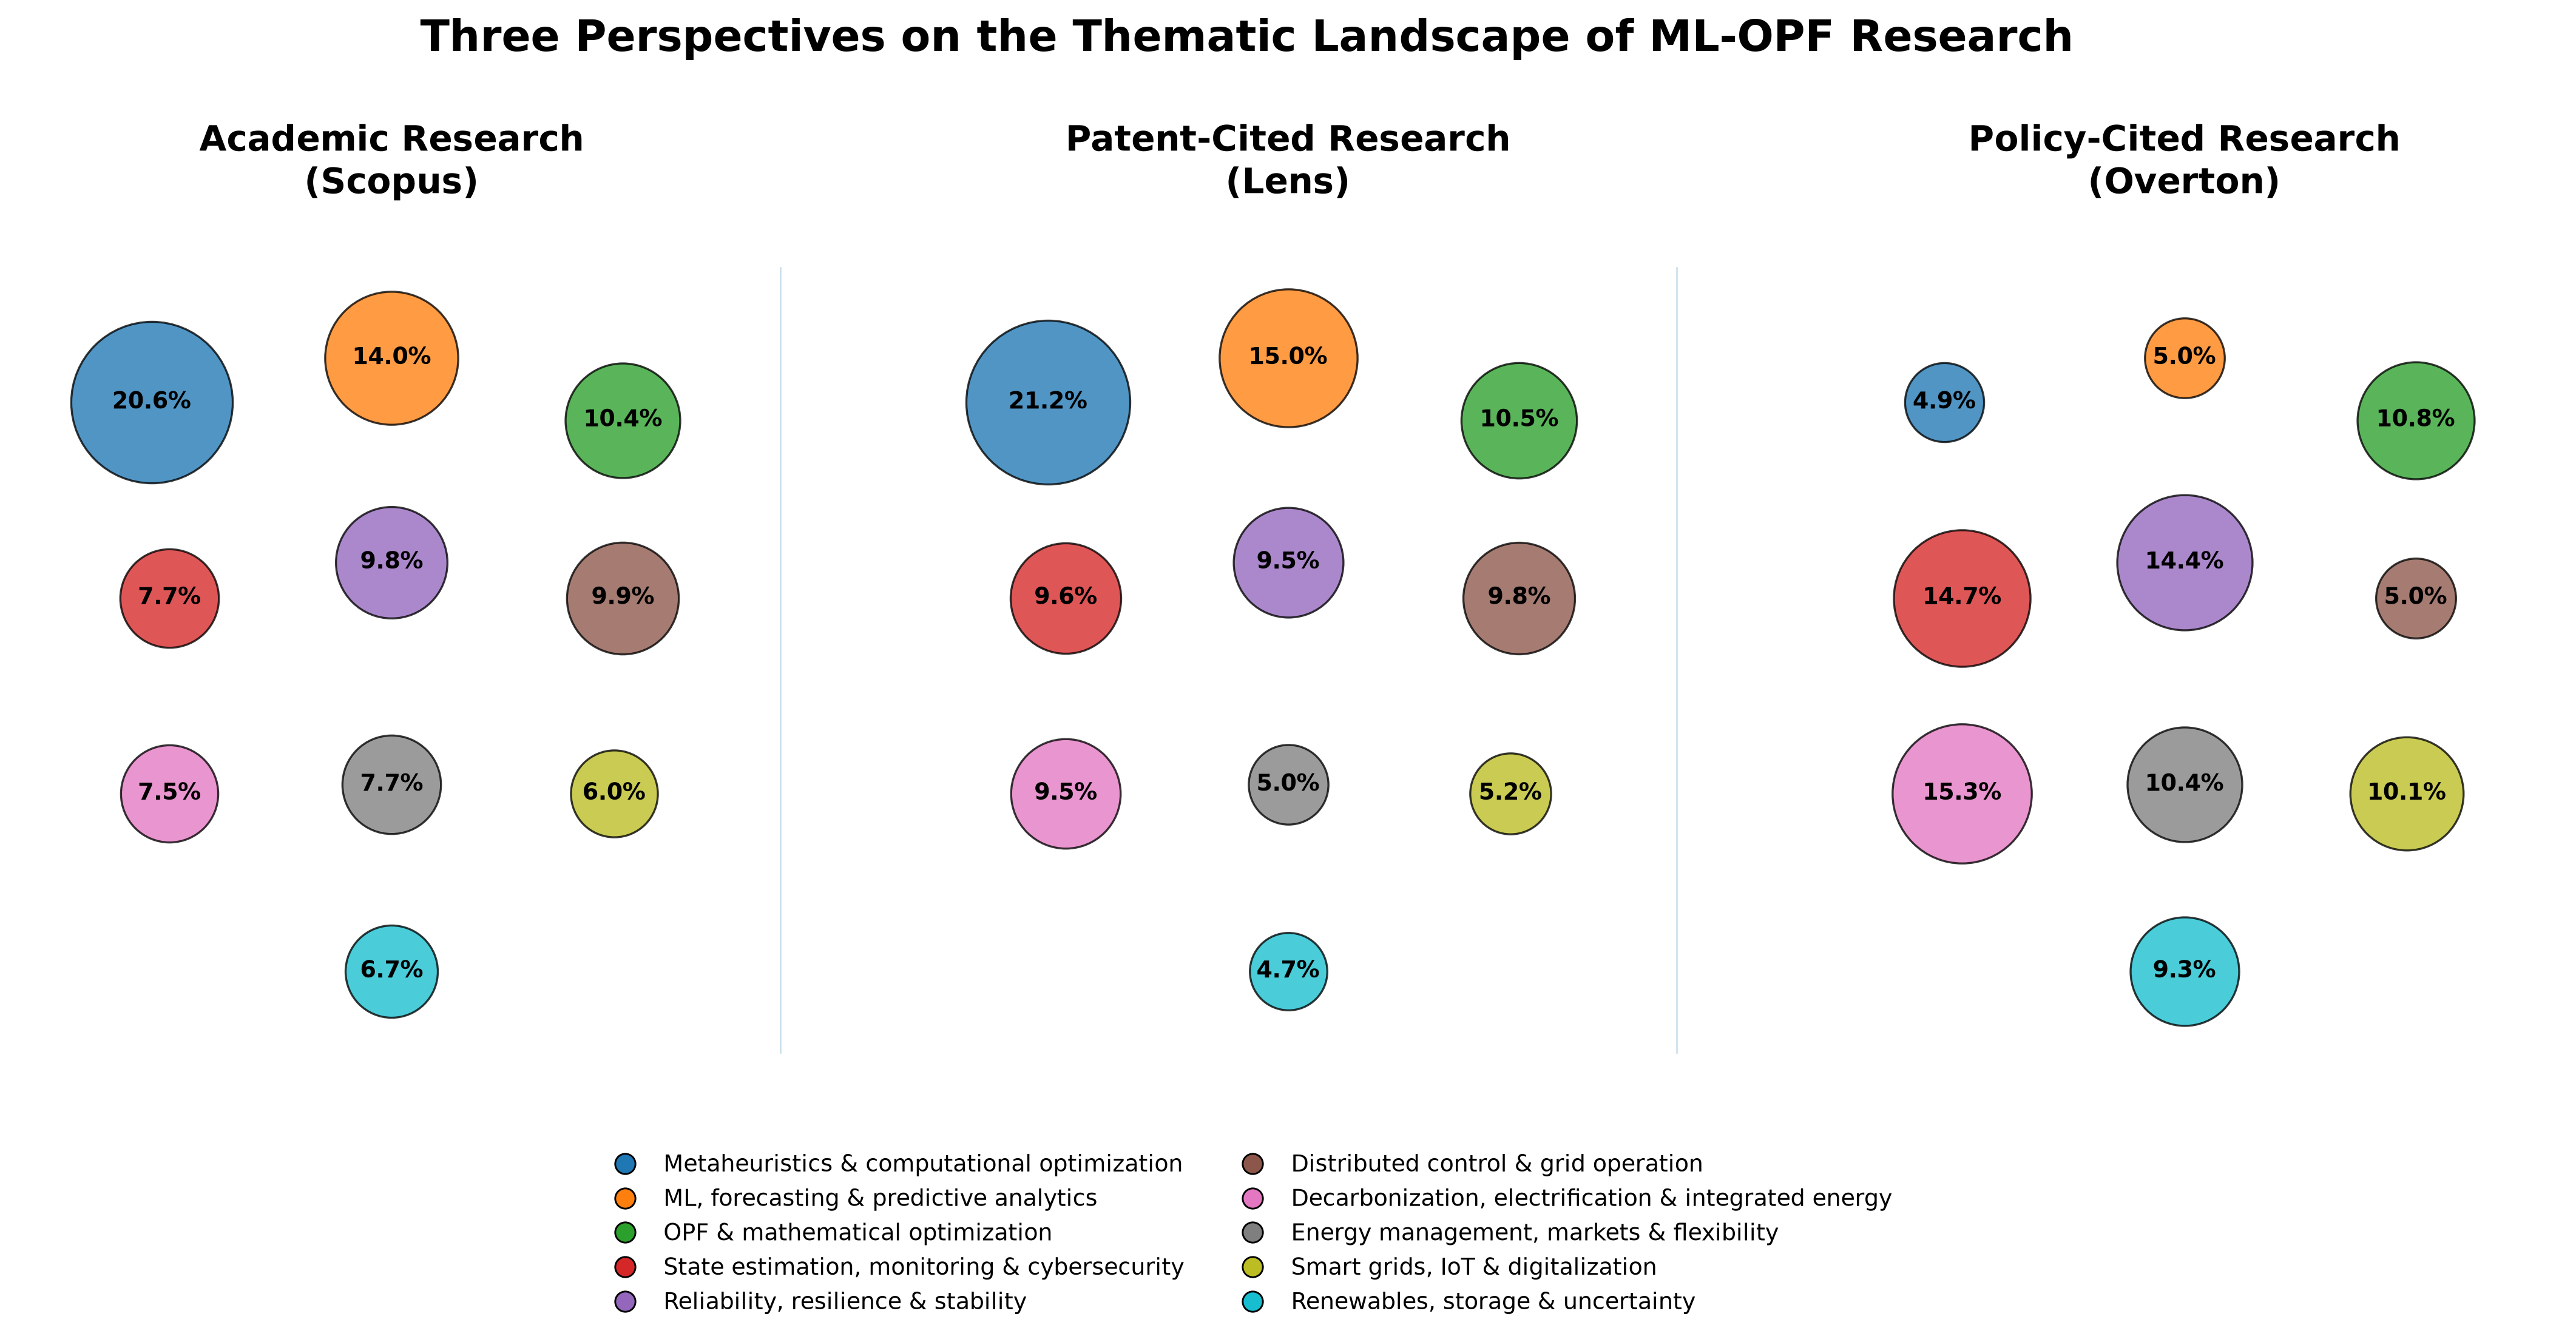

In [86]:
# ---------------------------------------------------------
# 10.4 Three-perspective thematic bubble landscape
# ---------------------------------------------------------

perspective_config = {

    "Academic": {
        "column": "Academic_Prevalence",
        "title": "Academic Research",
        "subtitle": "Scopus",
    },

    "Patent": {
        "column": "Patent_Prevalence",
        "title": "Patent-Cited Research",
        "subtitle": "Lens",
    },

    "Policy": {
        "column": "Policy_Prevalence",
        "title": "Policy-Cited Research",
        "subtitle": "Overton",
    },
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(
        18,
        7.2,
    ),
    dpi=300,
)


# ---------------------------------------------------------
# Bubble scaling
# ---------------------------------------------------------

all_prevalence = np.concatenate(
    [
        three_perspective_themes[
            config["column"]
        ]
        .to_numpy(
            dtype=float
        )

        for config
        in perspective_config.values()
    ]
)


max_prevalence = (
    all_prevalence.max()
)


MAX_BUBBLE_AREA = 4200


for ax in axes[:-1]:

    ax.plot(
        [1.02, 1.02],
        [0.04, 0.96],
        transform=ax.transAxes,
        clip_on=False,
        linewidth=0.6,
        alpha=0.25,
    )

for ax, (
    perspective,
    config,
) in zip(
    axes,
    perspective_config.items(),
):

    prevalence_column = (
        config[
            "column"
        ]
    )


    for _, row in (
        three_perspective_themes
        .iterrows()
    ):

        theme = (
            row[
                "Common_Macro_Theme"
            ]
        )

        prevalence = float(
            row[
                prevalence_column
            ]
        )


        x, y = (
            THEME_POSITIONS[
                theme
            ]
        )


        # Bubble area proportional to prevalence.
        bubble_area = (
            prevalence
            /
            max_prevalence
            *
            MAX_BUBBLE_AREA
        )


        ax.scatter(
            x,
            y,
            s=bubble_area,
            color=THEME_COLORS[
                theme
            ],
            alpha=0.78,
            edgecolors="black",
            linewidths=0.8,
            zorder=2,
        )


        # Percentage in bubble center.
        ax.text(
            x,
            y,
            f"{prevalence:.1f}%",
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            zorder=3,
        )


    ax.set_xlim(
        -2.1,
        2.1,
    )

    ax.set_ylim(
        -2.75,
        2.05,
    )


    ax.set_aspect(
        "equal"
    )


    ax.set_xticks([])
    ax.set_yticks([])


    for spine in (
        ax.spines.values()
    ):

        spine.set_visible(
            False
        )


    ax.set_title(
        (
            f"{config['title']}\n"
            f"({config['subtitle']})"
        ),
        fontsize=14,
        fontweight="bold",
        pad=16,
    )

# ---------------------------------------------------------
# 10.5 Common macro-theme legend
# ---------------------------------------------------------

THEME_LEGEND_LABELS = {

    "Metaheuristics and Computational Optimization":
        "Metaheuristics & computational optimization",

    "Machine Learning, Forecasting, and Predictive Analytics":
        "ML, forecasting & predictive analytics",

    "OPF and Mathematical Optimization":
        "OPF & mathematical optimization",

    "State Estimation, Monitoring, and Cybersecurity":
        "State estimation, monitoring & cybersecurity",

    "Reliability, Resilience, Security, and Stability":
        "Reliability, resilience & stability",

    "Distributed Control and Grid Operation":
        "Distributed control & grid operation",

    "Decarbonization, Electrification, and Integrated Energy Systems":
        "Decarbonization, electrification & integrated energy",

    "Energy Management, Markets, and Demand Flexibility":
        "Energy management, markets & flexibility",

    "Smart Grids, IoT, and Digitalization":
        "Smart grids, IoT & digitalization",

    "Renewable Energy, Storage, and Uncertainty":
        "Renewables, storage & uncertainty",
}

legend_handles = [

    plt.Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markerfacecolor=THEME_COLORS[theme],
        markeredgecolor="black",
        markeredgewidth=0.7,
        markersize=8,
        label=THEME_LEGEND_LABELS[theme],
    )

    for theme in COMMON_MACRO_THEMES
]

fig.suptitle(
    "Three Perspectives on the Thematic Landscape of ML-OPF Research",
    fontsize=17,
    fontweight="bold",
    y=0.985,
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=False,
    fontsize=9,
    columnspacing=2.0,
    handletextpad=0.7,
)

In [87]:
# ---------------------------------------------------------
# 10.6 Figure export
# ---------------------------------------------------------

THREE_PERSPECTIVE_BUBBLE_FIGURE = (
    COMPARISON_FIGURE_DIR
    / "academic_patent_policy_thematic_landscape.pdf"
)


fig.savefig(
    THREE_PERSPECTIVE_BUBBLE_FIGURE,
    format="pdf",
    bbox_inches="tight",
)


print(
    "Saved:",
    THREE_PERSPECTIVE_BUBBLE_FIGURE
)


plt.show()

Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\figures\academic_patent_policy_thematic_landscape.pdf


## 11. Three-Perspective Bubble Matrix

To complement the thematic landscape, a bubble matrix provides a more
structured comparison of macro-theme prevalence across the academic,
patent-cited, and policy-cited perspectives.

Rows represent the common macro-themes and columns represent the three
research perspectives. Bubble area is proportional to probability-weighted
macro-theme prevalence, while the numerical value inside each bubble reports
the corresponding percentage.

Unlike the thematic landscape, the matrix emphasizes direct row-wise
comparison and therefore makes thematic amplification, attenuation, and
cross-perspective consistency easier to identify.

In [88]:
# ---------------------------------------------------------
# 11.1 Prepare bubble-matrix data
# ---------------------------------------------------------

bubble_matrix_data = (
    three_perspective_long
    .copy()
)


# Preserve canonical theme order.
bubble_matrix_data[
    "Common_Macro_Theme"
] = pd.Categorical(
    bubble_matrix_data[
        "Common_Macro_Theme"
    ],
    categories=COMMON_MACRO_THEMES,
    ordered=True,
)


# Explicit perspective order.
PERSPECTIVE_ORDER = [
    "Academic",
    "Patent",
    "Policy",
]


bubble_matrix_data[
    "Perspective"
] = pd.Categorical(
    bubble_matrix_data[
        "Perspective"
    ],
    categories=PERSPECTIVE_ORDER,
    ordered=True,
)


bubble_matrix_data = (
    bubble_matrix_data
    .sort_values(
        [
            "Common_Macro_Theme",
            "Perspective",
        ]
    )
    .reset_index(
        drop=True
    )
)


display(
    bubble_matrix_data
)

,Common_Macro_Theme,Perspective,Prevalence_Percent
0,Metaheuristics and Computational Optimization,Academic,20.572435
1,Metaheuristics and Computational Optimization,Patent,21.179064
2,Metaheuristics and Computational Optimization,Policy,4.921997
3,"Machine Learning, Forecasting, and Predictive Analytics",Academic,13.964398
4,"Machine Learning, Forecasting, and Predictive Analytics",Patent,15.001093
5,"Machine Learning, Forecasting, and Predictive Analytics",Policy,5.022387
6,OPF and Mathematical Optimization,Academic,10.366663
7,OPF and Mathematical Optimization,Patent,10.514192
8,OPF and Mathematical Optimization,Policy,10.801742
9,"State Estimation, Monitoring, and Cybersecurity",Academic,7.657894


Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\figures\academic_patent_policy_bubble_matrix.pdf


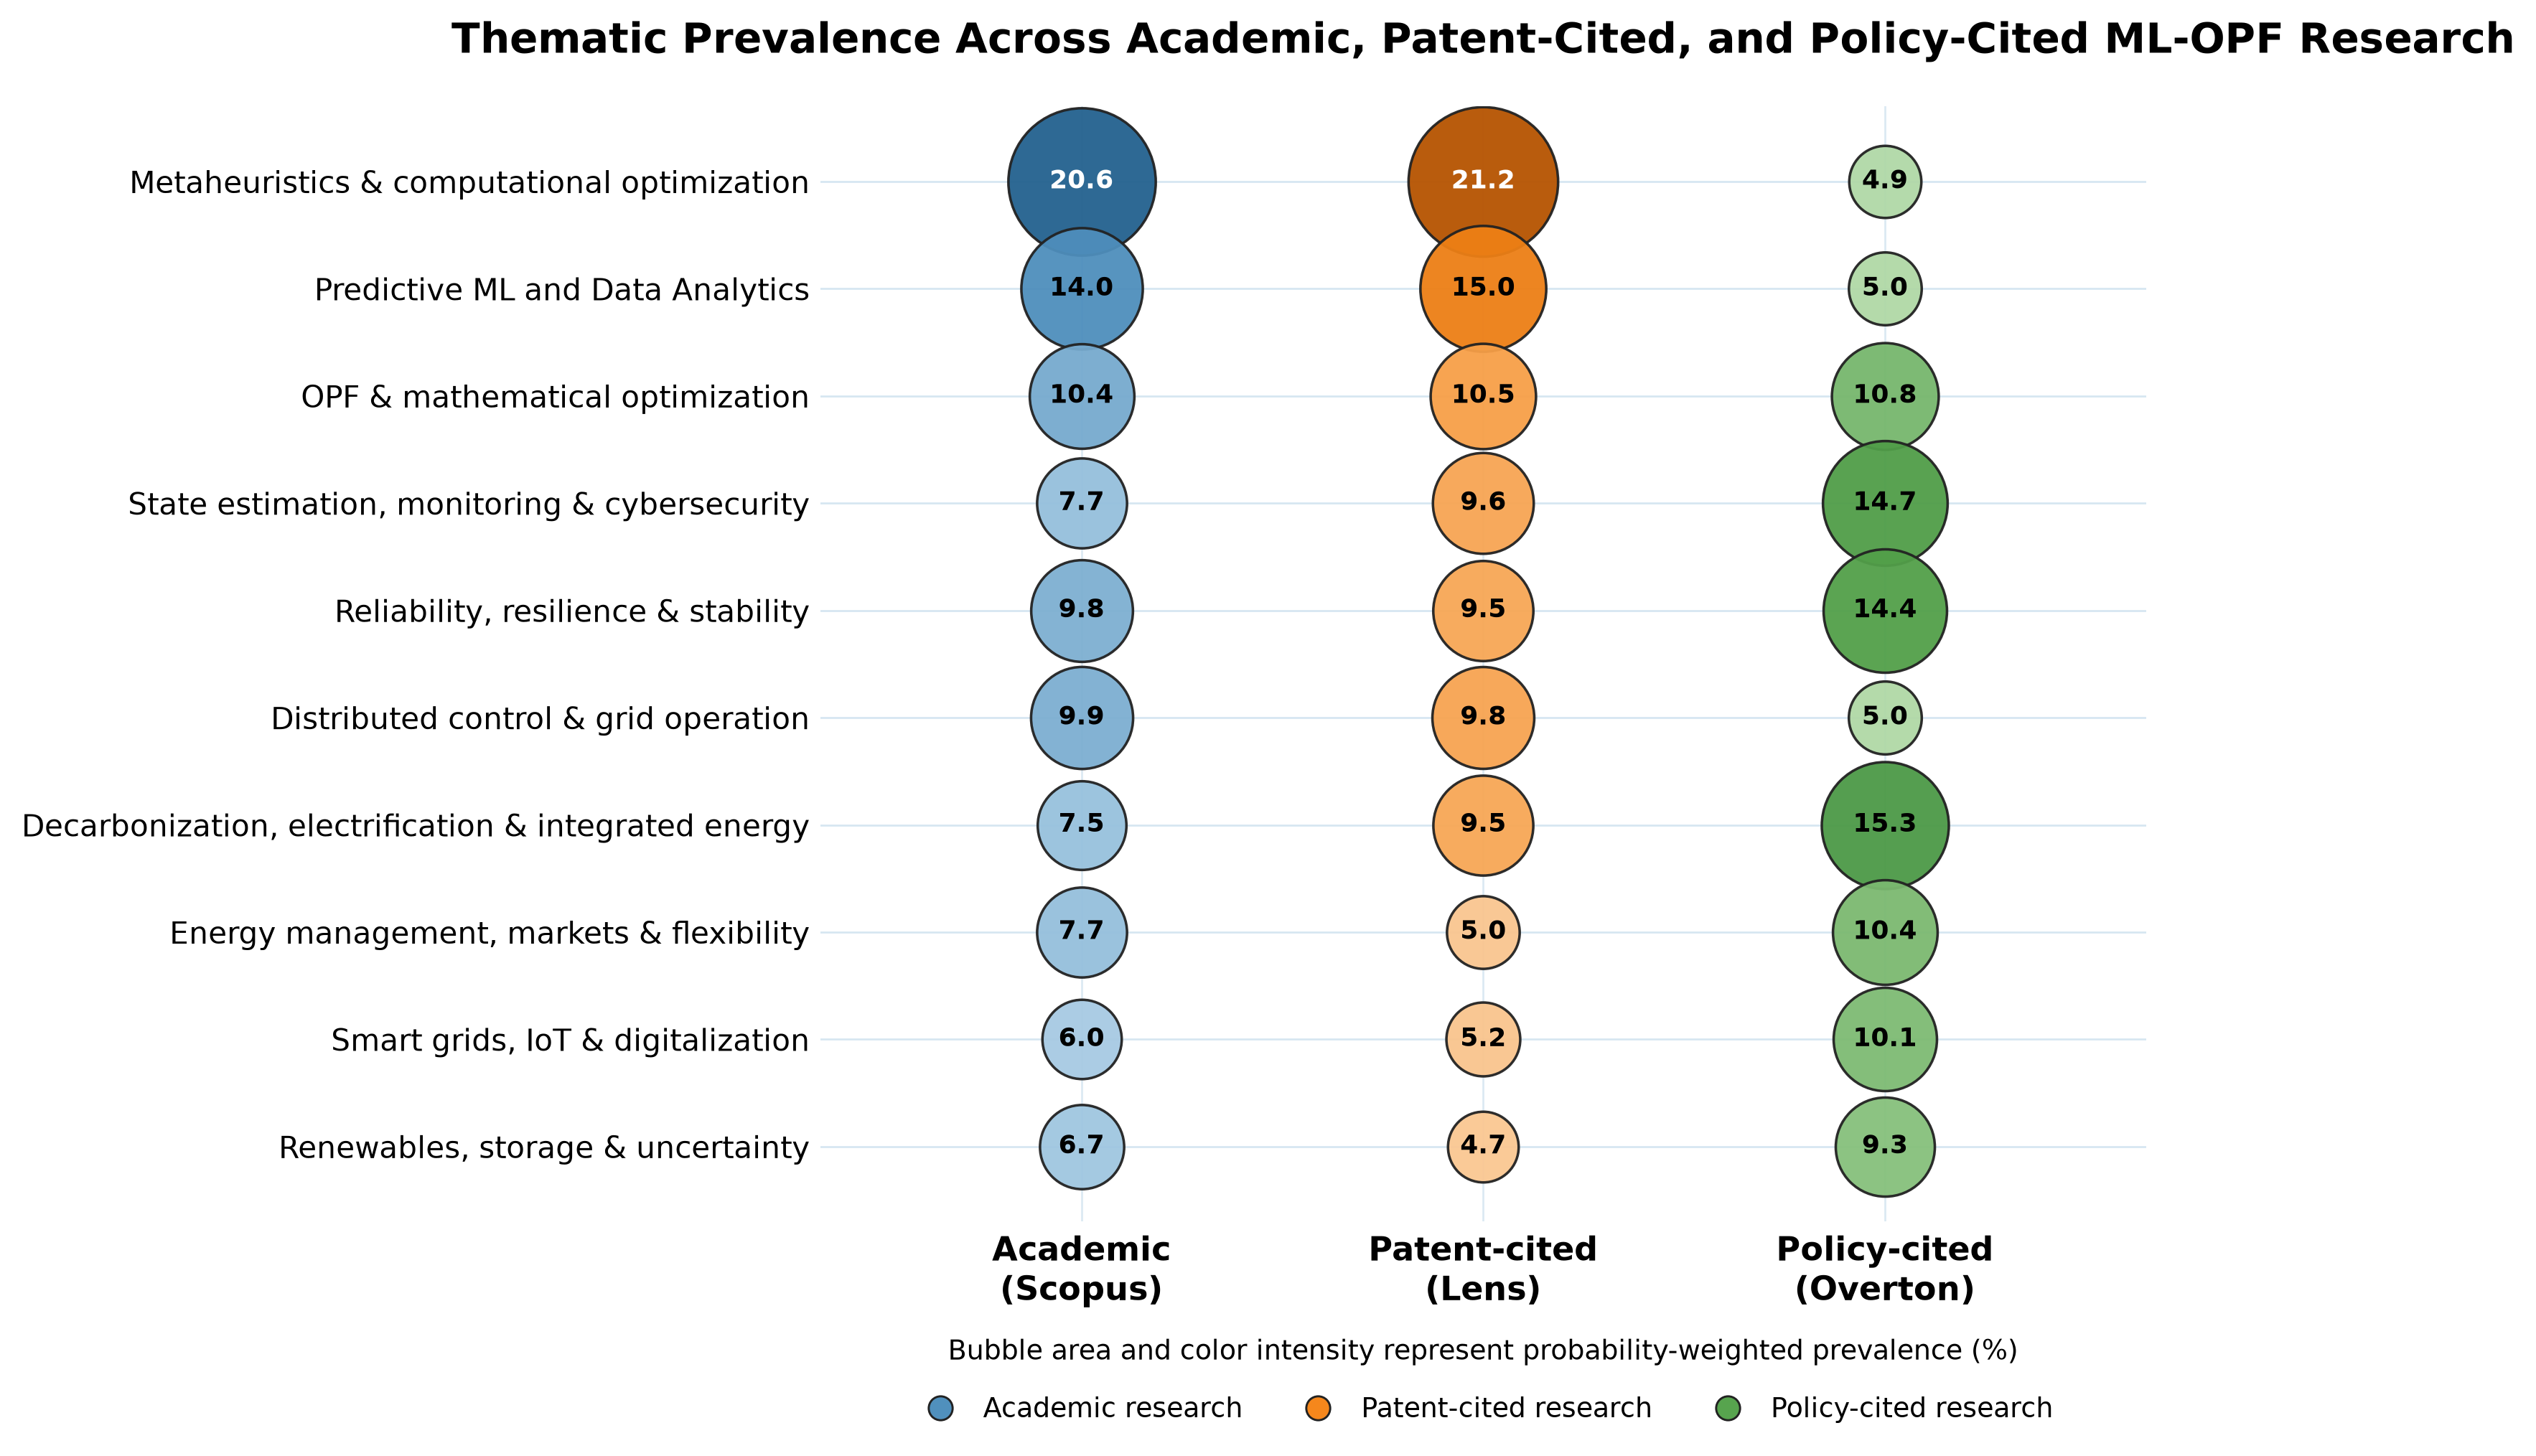

In [ ]:
# ---------------------------------------------------------
# 11.2 Compact row labels
# ---------------------------------------------------------

BUBBLE_MATRIX_LABELS = {

    "Metaheuristics and Computational Optimization":
        "Metaheuristics & computational optimization",

    "Machine Learning, Forecasting, and Predictive Analytics":
        "Predictive ML and Data Analytics",

    "OPF and Mathematical Optimization":
        "OPF & mathematical optimization",

    "State Estimation, Monitoring, and Cybersecurity":
        "State estimation, monitoring & cybersecurity",

    "Reliability, Resilience, Security, and Stability":
        "Reliability, resilience & stability",

    "Distributed Control and Grid Operation":
        "Distributed control & grid operation",

    "Decarbonization, Electrification, and Integrated Energy Systems":
        "Decarbonization, electrification & integrated energy",

    "Energy Management, Markets, and Demand Flexibility":
        "Energy management, markets & flexibility",

    "Smart Grids, IoT, and Digitalization":
        "Smart grids, IoT & digitalization",

    "Renewable Energy, Storage, and Uncertainty":
        "Renewables, storage & uncertainty",
}



Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\figures\academic_patent_policy_bubble_matrix.pdf


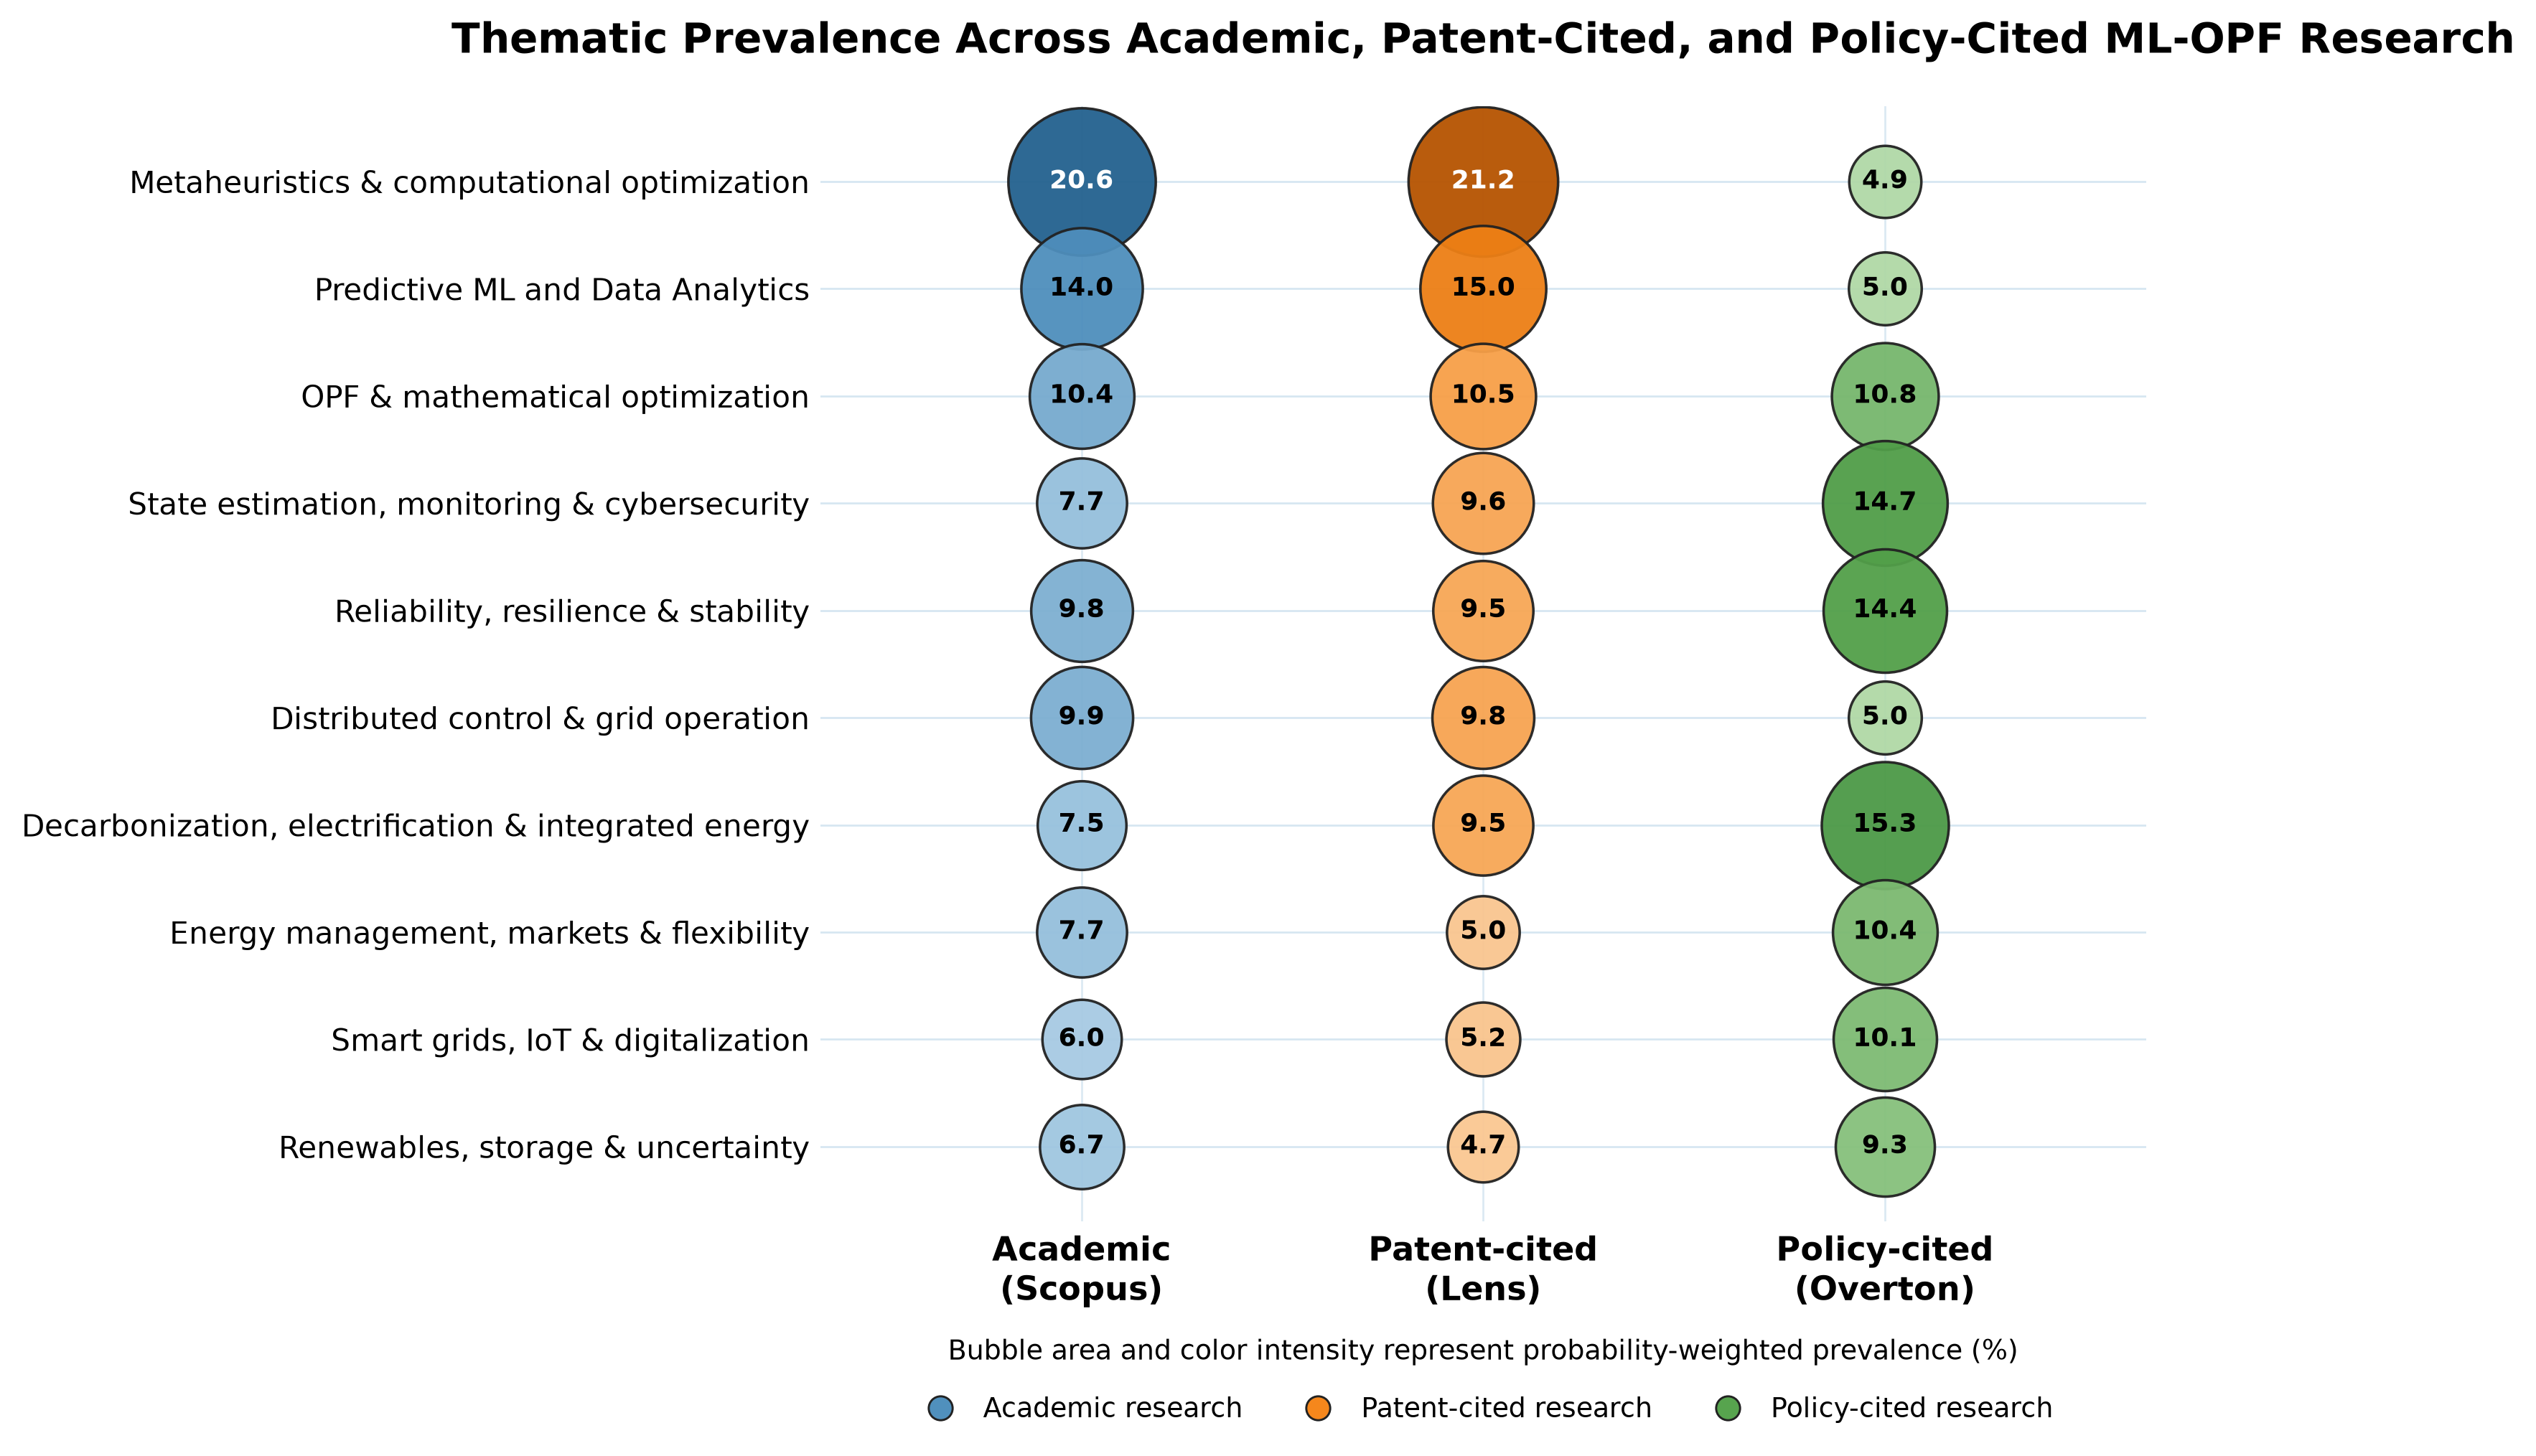

In [91]:
# ---------------------------------------------------------
# 11.3 Publication-quality three-perspective bubble matrix
# ---------------------------------------------------------

from matplotlib import colors
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
import numpy as np


# ---------------------------------------------------------
# Perspective order
# ---------------------------------------------------------

PERSPECTIVE_ORDER = [
    "Academic",
    "Patent",
    "Policy",
]


# ---------------------------------------------------------
# Perspective-specific sequential colormaps
#
# Light = lower prevalence
# Dark  = higher prevalence
#
# Each perspective retains its own color family:
# Academic -> blue
# Patent   -> orange
# Policy   -> green
# ---------------------------------------------------------

PERSPECTIVE_CMAPS = {

    "Academic":
        LinearSegmentedColormap.from_list(
            "academic_blue",
            [
                "#DCEAF5",
                "#9CC4DF",
                "#4C8DBB",
                "#1F5D8A",
            ],
        ),

    "Patent":
        LinearSegmentedColormap.from_list(
            "patent_orange",
            [
                "#FDE5CE",
                "#F8B875",
                "#F58518",
                "#B65300",
            ],
        ),

    "Policy":
        LinearSegmentedColormap.from_list(
            "policy_green",
            [
                "#DCEFD8",
                "#9DCE91",
                "#54A24B",
                "#256B2A",
            ],
        ),
}


# ---------------------------------------------------------
# X positions
# ---------------------------------------------------------

x_positions = {
    perspective:
        i
    for i, perspective
    in enumerate(
        PERSPECTIVE_ORDER
    )
}


# ---------------------------------------------------------
# Theme order
# ---------------------------------------------------------

theme_order = list(
    COMMON_MACRO_THEMES
)


# First theme at top.
y_positions = {
    theme:
        len(theme_order)
        - 1
        - i

    for i, theme
    in enumerate(
        theme_order
    )
}


# ---------------------------------------------------------
# Global prevalence normalization
#
# IMPORTANT:
# One normalization is used across ALL perspectives.
# Therefore, equal prevalence values receive comparable
# color intensity in all three columns.
# ---------------------------------------------------------

min_prevalence = float(
    bubble_matrix_data[
        "Prevalence_Percent"
    ]
    .min()
)


max_prevalence = float(
    bubble_matrix_data[
        "Prevalence_Percent"
    ]
    .max()
)


# Start at zero so darkness has an intuitive absolute scale.
color_norm = colors.Normalize(
    vmin=0,
    vmax=max_prevalence,
)


# ---------------------------------------------------------
# Bubble-size scaling
#
# Matplotlib scatter s= represents marker AREA.
# Therefore, linear scaling here means bubble area is
# proportional to prevalence.
# ---------------------------------------------------------

MAX_BUBBLE_AREA = 2500


def prevalence_to_area(
    prevalence,
):
    """
    Convert prevalence (%) to marker area.

    Bubble area is proportional to prevalence.
    """

    if max_prevalence <= 0:

        return 0


    return (
        prevalence
        /
        max_prevalence
        *
        MAX_BUBBLE_AREA
    )


# ---------------------------------------------------------
# Adaptive text color
#
# Dark bubbles -> white text
# Light bubbles -> black text
# ---------------------------------------------------------

def get_contrasting_text_color(
    rgba,
):
    """
    Select black or white text according to perceived
    luminance of the bubble face color.
    """

    r, g, b = rgba[:3]


    luminance = (
        0.2126 * r
        +
        0.7152 * g
        +
        0.0722 * b
    )


    if luminance < 0.50:

        return "white"

    return "black"


# ---------------------------------------------------------
# Create figure
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(
        10.8,
        7.4,
    ),
    dpi=300,
)


# ---------------------------------------------------------
# Background row guides
# ---------------------------------------------------------

for y in (
    y_positions.values()
):

    ax.axhline(
        y=y,
        linewidth=0.65,
        alpha=0.18,
        zorder=0,
    )


# ---------------------------------------------------------
# Column guides
# ---------------------------------------------------------

for x in (
    x_positions.values()
):

    ax.axvline(
        x=x,
        linewidth=0.65,
        alpha=0.16,
        zorder=0,
    )


# ---------------------------------------------------------
# Draw bubbles
# ---------------------------------------------------------

for _, row in (
    bubble_matrix_data
    .iterrows()
):

    perspective = str(
        row[
            "Perspective"
        ]
    )


    theme = str(
        row[
            "Common_Macro_Theme"
        ]
    )


    prevalence = float(
        row[
            "Prevalence_Percent"
        ]
    )


    x = (
        x_positions[
            perspective
        ]
    )


    y = (
        y_positions[
            theme
        ]
    )


    # -----------------------------------------------------
    # Bubble area
    # -----------------------------------------------------

    bubble_area = (
        prevalence_to_area(
            prevalence
        )
    )


    # -----------------------------------------------------
    # Bubble color
    #
    # Higher prevalence -> darker shade within the
    # perspective's color family.
    # -----------------------------------------------------

    face_color = (
        PERSPECTIVE_CMAPS[
            perspective
        ](
            color_norm(
                prevalence
            )
        )
    )


    # -----------------------------------------------------
    # Draw bubble
    # -----------------------------------------------------

    ax.scatter(
        x,
        y,
        s=bubble_area,
        color=face_color,
        alpha=0.95,
        edgecolors="#222222",
        linewidths=0.85,
        zorder=3,
    )


    # -----------------------------------------------------
    # Adaptive label color
    # -----------------------------------------------------

    text_color = (
        get_contrasting_text_color(
            face_color
        )
    )


    # -----------------------------------------------------
    # Percentage label
    # -----------------------------------------------------

    ax.text(
        x,
        y,
        f"{prevalence:.1f}",
        ha="center",
        va="center",
        fontsize=8.7,
        fontweight="bold",
        color=text_color,
        zorder=4,
    )


# ---------------------------------------------------------
# X-axis labels
# ---------------------------------------------------------

ax.set_xticks(
    [
        x_positions[
            perspective
        ]
        for perspective
        in PERSPECTIVE_ORDER
    ]
)


ax.set_xticklabels(
    [
        "Academic\n(Scopus)",
        "Patent-cited\n(Lens)",
        "Policy-cited\n(Overton)",
    ],
    fontsize=11,
    fontweight="bold",
)


# ---------------------------------------------------------
# Y-axis labels
# ---------------------------------------------------------

ax.set_yticks(
    [
        y_positions[
            theme
        ]
        for theme
        in theme_order
    ]
)


ax.set_yticklabels(
    [
        BUBBLE_MATRIX_LABELS[
            theme
        ]
        for theme
        in theme_order
    ],
    fontsize=10,
)


# ---------------------------------------------------------
# Axis limits
# ---------------------------------------------------------

ax.set_xlim(
    -0.65,
    len(
        PERSPECTIVE_ORDER
    )
    - 0.35,
)


ax.set_ylim(
    -0.7,
    len(
        theme_order
    )
    - 0.3,
)


# ---------------------------------------------------------
# Remove frame
# ---------------------------------------------------------

for spine in (
    ax.spines.values()
):

    spine.set_visible(
        False
    )


ax.tick_params(
    axis="both",
    length=0,
)


# ---------------------------------------------------------
# Title
# ---------------------------------------------------------

ax.set_title(
    (
        "Thematic Prevalence Across Academic, "
        "Patent-Cited, and Policy-Cited ML-OPF Research"
    ),
    fontsize=14,
    fontweight="bold",
    pad=18,
)


# ---------------------------------------------------------
# Explanatory note
# ---------------------------------------------------------

ax.text(
    0.5,
    -0.105,
    (
        "Bubble area and color intensity represent "
        "probability-weighted prevalence (%)"
    ),
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=9,
)


# ---------------------------------------------------------
# Perspective color-family legend
# ---------------------------------------------------------

perspective_handles = [

    plt.Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markersize=8,
        markerfacecolor=(
            PERSPECTIVE_CMAPS[
                perspective
            ](
                color_norm(
                    max_prevalence
                    * 0.65
                )
            )
        ),
        markeredgecolor="#222222",
        markeredgewidth=0.7,
        label=label,
    )

    for perspective, label
    in [
        (
            "Academic",
            "Academic research",
        ),
        (
            "Patent",
            "Patent-cited research",
        ),
        (
            "Policy",
            "Policy-cited research",
        ),
    ]
]


ax.legend(
    handles=perspective_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        -0.135,
    ),
    ncol=3,
    frameon=False,
    fontsize=9,
    handletextpad=0.6,
    columnspacing=1.8,
)


# ---------------------------------------------------------
# Layout
# ---------------------------------------------------------

fig.subplots_adjust(
    left=0.40,
    right=0.97,
    top=0.90,
    bottom=0.20,
)


# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

THREE_PERSPECTIVE_MATRIX_FIGURE = (
    COMPARISON_FIGURE_DIR
    / "academic_patent_policy_bubble_matrix.pdf"
)


fig.savefig(
    THREE_PERSPECTIVE_MATRIX_FIGURE,
    format="pdf",
    bbox_inches="tight",
)


print(
    "Saved:",
    THREE_PERSPECTIVE_MATRIX_FIGURE
)


plt.show()

In [90]:
# ---------------------------------------------------------
# 11.6 Save bubble matrix
# ---------------------------------------------------------

THREE_PERSPECTIVE_MATRIX_FIGURE = (
    COMPARISON_FIGURE_DIR
    / "academic_patent_policy_bubble_matrix.pdf"
)


fig.savefig(
    THREE_PERSPECTIVE_MATRIX_FIGURE,
    format="pdf",
    bbox_inches="tight",
)


print(
    "Saved:",
    THREE_PERSPECTIVE_MATRIX_FIGURE
)


plt.show()

Saved: M:\projects_latex\review_paper_2\output\academic_patent_policy_comparison\figures\academic_patent_policy_bubble_matrix.pdf


## 12. Heatmap / Bubble Matrix

## 13. Export Manuscript Tables and Figures

## 14. Reproducibility Checks